# [5.8] Discrete Diffusion Language Models (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part8_diffusion_language_models/5.8_Discrete_Diffusion_Language_Models_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part8_diffusion_language_models/5.8_Discrete_Diffusion_Language_Models_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

## Content & Learning Objectives

- Implement noising, diffusion loss, reverse probabilities and text sampling.
- Compare the exact copy task with arithmetic, QA and TinyStories continuations.
- Inspect matched autoregressive baselines and shuffled-supervision controls.
- Explain development selection, exposed sampler variants and weak generations.

# 1️⃣ Exact copy grammar

## [5.8] Discrete Diffusion LMs: From Copying Digits to Generating Words

By the end of this notebook, you will have shown when a small masked denoiser
uses its input to generate an answer, by watching actual token decisions and
comparing held-out strings with shuffled supervision and a matched causal model.

## Core question

**Which tokens should a denoiser commit first, and what does a confident decision actually tell us?**

Consider `Add: 17+24 =` followed by 24 MASK slots. The answer is `41`, but neither
its token count nor its EOS position is supplied to the sampler. A model must
decide the answer, where to end it, and which other positions contain fill tokens.
We start with the smaller puzzle `[a,b] → [a,b,a,a,b,b]`, where every answer is
known exactly, then carry the same questions into arithmetic, parentheses,
context-dependent questions and a pinned TinyStories subset.

## What you will implement

- Implement and test noising, the finite absorbing diffusion loss and reverse probabilities.
- Separate confidence-based reveal order, random reveal order and ancestral sampling.
- Build the same Transformer with bidirectional or causal attention and test its KV cache.
- Train matched models and retain development-selected checkpoints and shuffled controls.
- Read actual word trajectories, predictive entropy, stable commitment and generation cost.
- Explain why a correct alternative string, low loss and fluent-looking text are different claims.

The copy warm-up is a short first session. The text progression is a longer
self-study session with 13 further implementation groups. Numerical exercises
run on CPU; the complete training and timing study uses CUDA. Keep an experiment
log: predict each control before running it, record surprises, and change one
sampling choice at a time. Original ARENA's Transformer-from-scratch chapter
provides the prerequisite attention, training and cache concepts.

## Part A — an exact copy grammar

In [ ]:
from __future__ import annotations

MAIN = __name__ == "__main__"

import json

import os

import hashlib

import time

import statistics

from collections.abc import Callable

import sys

from dataclasses import dataclass

from pathlib import Path

import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

import numpy as np

import pandas as pd

import torch as t

import torch.nn as nn

import torch.nn.functional as F

from IPython.display import display

chapter = "chapter5_modern_architectures"

root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())

chapter_dir = root_dir / chapter

section_dir = chapter_dir / "exercises" / "part8_diffusion_language_models"

for path in [root_dir, chapter_dir / "exercises"]:
    if str(path) not in sys.path:
        sys.path.append(str(path))

import part8_diffusion_language_models.tests as tests

NUMERICAL_ONLY = os.environ.get("ARENA_DIFFUSION_NUMERICAL_ONLY", "0") == "1"

RUN_COPY_WARMUP = not NUMERICAL_ONLY

RUN_TEXT_STUDY = not NUMERICAL_ONLY

if RUN_TEXT_STUDY and not t.cuda.is_available():
    raise RuntimeError("The full training/timing study requires CUDA; numerical exercises can run on CPU.")

device = t.device("cuda" if t.cuda.is_available() and not NUMERICAL_ONLY else "cpu")

t.set_num_threads(4)

t.set_float32_matmul_precision("highest")

output_dir = Path(os.environ.get("ARENA_DIFFUSION_OUTPUT_DIRECTORY", str(section_dir / "artifacts" / "learner_text_run")))

assets_dir = output_dir / "figures"

assets_dir.mkdir(parents=True, exist_ok=True)

print(f"torch={t.__version__} | device={device} | numerical only={NUMERICAL_ONLY}")

@dataclass(frozen=True)
class DiscreteDiffusionSchedule:
    mask_probs: t.Tensor
    mask_token_id: int

    @property
    def num_steps(self) -> int:
        return int(self.mask_probs.numel())

@dataclass(frozen=True)
class NoisingResult:
    noisy_tokens: t.Tensor
    mask: t.Tensor
    timesteps: t.Tensor

@dataclass(frozen=True)
class DenoisingStepStats:
    step: int
    mask_fraction: float
    mean_entropy: float
    committed_fraction: float

## Cold open: the phenomenon

For prefix `[3, 7]`, the exact target is `[3, 7, 3, 3, 7, 7]`. A diffusion LM begins with an intact condition and a masked suffix. Each reverse step predicts every suffix position, keeps the most confident guesses, and remasks the rest.

The challenge is not producing one plausible final row. We need to show that the model learned the rule on held-out prefixes, that its decisions evolve coherently, and that a matched shuffled-label model fails.

In [ ]:
cold_open = pd.DataFrame({
    "stage": ["condition", "high noise", "partial commitment", "target"],
    "tokens": [
        [3, 7, "MASK", "MASK", "MASK", "MASK"],
        [3, 7, "MASK", "MASK", "MASK", "MASK"],
        [3, 7, 3, 3, "MASK", "MASK"],
        [3, 7, 3, 3, 7, 7],
    ],
})

display(cold_open)

### Exercise - build the masking schedule

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

At timestep `t`, each token is independently replaced by `MASK` with probability `p_t`. Implement the schedule before touching a model.

<details><summary>Help - reveal a hint</summary>

`torch.linspace` gives the exact schedule. Index it with the batch timesteps, then average the selected probabilities.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_linear_mask_schedule_and_expected_fraction` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def linear_mask_schedule(
    num_steps: int,
    *,
    mask_token_id: int,
    min_mask_prob: float = 0.0,
    max_mask_prob: float = 1.0,
) -> DiscreteDiffusionSchedule:
    if num_steps <= 0:
        raise ValueError("num_steps must be positive.")
    if not 0 <= min_mask_prob <= max_mask_prob <= 1:
        raise ValueError("mask probabilities must satisfy 0 <= min <= max <= 1.")
    return DiscreteDiffusionSchedule(
        mask_probs=t.linspace(min_mask_prob, max_mask_prob, num_steps),
        mask_token_id=mask_token_id,
    )


def expected_mask_fraction(schedule: DiscreteDiffusionSchedule, timesteps: t.Tensor) -> float:
    probs = schedule.mask_probs.to(device=timesteps.device, dtype=t.float32)[timesteps]
    return probs.mean().item()
```

</details>

In [ ]:
def linear_mask_schedule(
    num_steps: int,
    *,
    mask_token_id: int,
    min_mask_prob: float = 0.0,
    max_mask_prob: float = 1.0,
) -> DiscreteDiffusionSchedule:
    raise NotImplementedError()

def expected_mask_fraction(schedule: DiscreteDiffusionSchedule, timesteps: t.Tensor) -> float:
    raise NotImplementedError()

tests.test_linear_mask_schedule_and_expected_fraction(linear_mask_schedule, expected_mask_fraction)


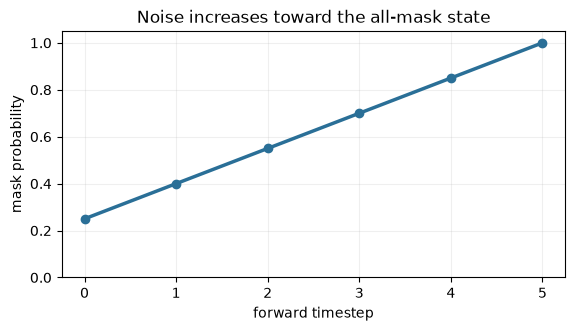

In [ ]:
schedule_preview = linear_mask_schedule(6, mask_token_id=10, min_mask_prob=0.25, max_mask_prob=1.0)

plt.figure(figsize=(6.5, 3.2))

plt.plot(range(schedule_preview.num_steps), schedule_preview.mask_probs, marker="o", color="#2a6f97", lw=2.5)

plt.ylim(0, 1.05)

plt.xlabel("forward timestep")

plt.ylabel("mask probability")

plt.title("Noise increases toward the all-mask state")

plt.grid(alpha=0.2)

plt.show()

<details><summary>Solution</summary>

```python
def linear_mask_schedule(
    num_steps: int,
    *,
    mask_token_id: int,
    min_mask_prob: float = 0.0,
    max_mask_prob: float = 1.0,
) -> DiscreteDiffusionSchedule:
    if num_steps <= 0:
        raise ValueError("num_steps must be positive.")
    if not 0 <= min_mask_prob <= max_mask_prob <= 1:
        raise ValueError("mask probabilities must satisfy 0 <= min <= max <= 1.")
    return DiscreteDiffusionSchedule(
        mask_probs=t.linspace(min_mask_prob, max_mask_prob, num_steps),
        mask_token_id=mask_token_id,
    )

def expected_mask_fraction(schedule: DiscreteDiffusionSchedule, timesteps: t.Tensor) -> float:
    probs = schedule.mask_probs.to(device=timesteps.device, dtype=t.float32)[timesteps]
    return probs.mean().item()

tests.test_linear_mask_schedule_and_expected_fraction(linear_mask_schedule, expected_mask_fraction)
```
</details>

![Analytic mask schedule](../../instructions/assets/diffusion_lm_mask_schedule.png)

### Exercise - apply forward noising

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Draw one Bernoulli decision per token. The test includes the exact zero-noise and all-noise endpoints and a seeded mixed case.

Common bug: drawing one random value per sequence produces all-clean or all-masked rows instead of mixed corruption patterns.

<details><summary>Help - reveal a hint</summary>

Broadcast one probability per batch item over the sequence dimension. Do not draw one mask decision for the whole sequence.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_forward_noising_extremes_and_seeded_masks` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def apply_forward_noising(
    input_ids: t.Tensor,
    timesteps: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    generator: t.Generator | None = None,
) -> NoisingResult:
    if input_ids.ndim != 2:
        raise ValueError("input_ids must have shape (batch, seq).")
    if timesteps.shape != (input_ids.shape[0],):
        raise ValueError("timesteps must have shape (batch,).")
    if timesteps.min() < 0 or timesteps.max() >= schedule.num_steps:
        raise ValueError("timesteps are out of range for schedule.")
    probs = schedule.mask_probs.to(device=input_ids.device, dtype=t.float32)[timesteps]
    random_values = t.rand(input_ids.shape, generator=generator, device=input_ids.device)
    mask = random_values < probs[:, None]
    noisy = input_ids.clone()
    noisy[mask] = schedule.mask_token_id
    return NoisingResult(noisy_tokens=noisy, mask=mask, timesteps=timesteps)
```

</details>

In [ ]:
def apply_forward_noising(
    input_ids: t.Tensor,
    timesteps: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    generator: t.Generator | None = None,
) -> NoisingResult:
    raise NotImplementedError()

tests.test_forward_noising_extremes_and_seeded_masks(apply_forward_noising, linear_mask_schedule)


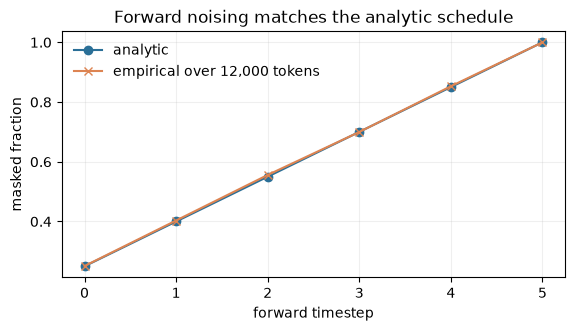

In [ ]:
probe_tokens = t.arange(6).repeat(2000, 1)

empirical = []

for timestep in range(schedule_preview.num_steps):
    ts = t.full((len(probe_tokens),), timestep)
    gen = t.Generator().manual_seed(100 + timestep)
    empirical.append(apply_forward_noising(probe_tokens, ts, schedule_preview, generator=gen).mask.float().mean().item())

plt.figure(figsize=(6.5, 3.2))

plt.plot(schedule_preview.mask_probs, label="analytic", marker="o", color="#2a6f97")

plt.plot(empirical, label="empirical over 12,000 tokens", marker="x", color="#dd8452")

plt.xlabel("forward timestep")

plt.ylabel("masked fraction")

plt.title("Forward noising matches the analytic schedule")

plt.legend(frameon=False)

plt.grid(alpha=0.2)

plt.show()

<details><summary>Solution</summary>

```python
def apply_forward_noising(
    input_ids: t.Tensor,
    timesteps: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    generator: t.Generator | None = None,
) -> NoisingResult:
    if input_ids.ndim != 2:
        raise ValueError("input_ids must have shape (batch, seq).")
    if timesteps.shape != (input_ids.shape[0],):
        raise ValueError("timesteps must have shape (batch,).")
    if timesteps.min() < 0 or timesteps.max() >= schedule.num_steps:
        raise ValueError("timesteps are out of range for schedule.")
    probs = schedule.mask_probs.to(device=input_ids.device, dtype=t.float32)[timesteps]
    random_values = t.rand(input_ids.shape, generator=generator, device=input_ids.device)
    mask = random_values < probs[:, None]
    noisy = input_ids.clone()
    noisy[mask] = schedule.mask_token_id
    return NoisingResult(noisy_tokens=noisy, mask=mask, timesteps=timesteps)

tests.test_forward_noising_extremes_and_seeded_masks(apply_forward_noising, linear_mask_schedule)
```
</details>

![Analytic and empirical noising fractions](../../instructions/assets/diffusion_lm_noising_calibration.png)

### Exercise - compute masked denoising loss

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Only corrupted positions contribute to the objective. Visible tokens are context; rewarding the model for copying them would inflate performance.

<details><summary>Help - reveal a hint</summary>

Boolean-index all three tensors with `mask`, then call cross entropy on the selected logits and targets.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_masked_denoising_loss_uses_only_masked_positions` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def masked_denoising_loss(logits: t.Tensor, target_ids: t.Tensor, mask: t.Tensor) -> t.Tensor:
    if logits.shape[:-1] != target_ids.shape or target_ids.shape != mask.shape:
        raise ValueError("logits, target_ids, and mask shapes are incompatible.")
    if not mask.any():
        raise ValueError("masked_denoising_loss requires at least one masked token.")
    return F.cross_entropy(logits[mask.bool()].float(), target_ids[mask.bool()].long())
```

</details>

In [ ]:
def masked_denoising_loss(logits: t.Tensor, target_ids: t.Tensor, mask: t.Tensor) -> t.Tensor:
    raise NotImplementedError()

tests.test_masked_denoising_loss_uses_only_masked_positions(masked_denoising_loss)

<details><summary>Solution</summary>

```python
def masked_denoising_loss(logits: t.Tensor, target_ids: t.Tensor, mask: t.Tensor) -> t.Tensor:
    if logits.shape[:-1] != target_ids.shape or target_ids.shape != mask.shape:
        raise ValueError("logits, target_ids, and mask shapes are incompatible.")
    if not mask.any():
        raise ValueError("masked_denoising_loss requires at least one masked token.")
    return F.cross_entropy(logits[mask.bool()].float(), target_ids[mask.bool()].long())

tests.test_masked_denoising_loss_uses_only_masked_positions(masked_denoising_loss)
```
</details>

### Exercise - remask low-confidence tokens

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Predict every position, rank positions by confidence, and remask the least confident fraction. Implement uniform remasking as a matched mask-budget baseline.

<details><summary>Help - reveal a hint</summary>

Use `softmax(...).max(-1)` for confidence and `topk(..., largest=False)` for the positions to remask.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_confidence_remask_entropy_and_uniform_control` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def token_entropy(logits: t.Tensor) -> t.Tensor:
    log_probs = F.log_softmax(logits.float(), dim=-1)
    probs = log_probs.exp()
    return -(probs * log_probs).sum(dim=-1)


def confidence_remask(
    logits: t.Tensor,
    current_tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
) -> t.Tensor:
    if not 0 <= next_mask_fraction <= 1:
        raise ValueError("next_mask_fraction must be in [0, 1].")
    probs = F.softmax(logits.float(), dim=-1)
    confidence, predictions = probs.max(dim=-1)
    new_tokens = predictions.to(dtype=current_tokens.dtype)
    num_to_mask = int(round(next_mask_fraction * current_tokens.shape[1]))
    if num_to_mask == 0:
        return new_tokens
    low_conf = confidence.topk(k=num_to_mask, dim=-1, largest=False).indices
    new_tokens.scatter_(1, low_conf, mask_token_id)
    return new_tokens


def uniform_remask(
    tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
    generator: t.Generator | None = None,
) -> t.Tensor:
    if not 0 <= next_mask_fraction <= 1:
        raise ValueError("next_mask_fraction must be in [0, 1].")
    num_to_mask = int(round(next_mask_fraction * tokens.shape[1]))
    if num_to_mask == 0:
        return tokens.clone()
    scores = t.rand(tokens.shape, generator=generator, device=tokens.device)
    chosen = scores.topk(k=num_to_mask, dim=-1, largest=False).indices
    remasked = tokens.clone()
    remasked.scatter_(1, chosen, mask_token_id)
    return remasked
```

</details>

In [ ]:
def token_entropy(logits: t.Tensor) -> t.Tensor:
    raise NotImplementedError()

def confidence_remask(
    logits: t.Tensor,
    current_tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
) -> t.Tensor:
    raise NotImplementedError()

def uniform_remask(
    tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
    generator: t.Generator | None = None,
) -> t.Tensor:
    raise NotImplementedError()

tests.test_confidence_remask_entropy_and_uniform_control(confidence_remask, token_entropy, uniform_remask)

<details><summary>Solution</summary>

```python
def token_entropy(logits: t.Tensor) -> t.Tensor:
    log_probs = F.log_softmax(logits.float(), dim=-1)
    probs = log_probs.exp()
    return -(probs * log_probs).sum(dim=-1)

def confidence_remask(
    logits: t.Tensor,
    current_tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
) -> t.Tensor:
    if not 0 <= next_mask_fraction <= 1:
        raise ValueError("next_mask_fraction must be in [0, 1].")
    probs = F.softmax(logits.float(), dim=-1)
    confidence, predictions = probs.max(dim=-1)
    new_tokens = predictions.to(dtype=current_tokens.dtype)
    num_to_mask = int(round(next_mask_fraction * current_tokens.shape[1]))
    if num_to_mask == 0:
        return new_tokens
    low_conf = confidence.topk(k=num_to_mask, dim=-1, largest=False).indices
    new_tokens.scatter_(1, low_conf, mask_token_id)
    return new_tokens

def uniform_remask(
    tokens: t.Tensor,
    *,
    mask_token_id: int,
    next_mask_fraction: float,
    generator: t.Generator | None = None,
) -> t.Tensor:
    if not 0 <= next_mask_fraction <= 1:
        raise ValueError("next_mask_fraction must be in [0, 1].")
    num_to_mask = int(round(next_mask_fraction * tokens.shape[1]))
    if num_to_mask == 0:
        return tokens.clone()
    scores = t.rand(tokens.shape, generator=generator, device=tokens.device)
    chosen = scores.topk(k=num_to_mask, dim=-1, largest=False).indices
    remasked = tokens.clone()
    remasked.scatter_(1, chosen, mask_token_id)
    return remasked

tests.test_confidence_remask_entropy_and_uniform_control(confidence_remask, token_entropy, uniform_remask)
```
</details>

### Exercise - make an oracle sampler work first

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Before training, use an oracle denoiser with a known target. This isolates reverse-process bugs from learning failures.

<details><summary>Help - reveal a hint</summary>

Iterate through the schedule in reverse. At each non-final step, predict all tokens and remask according to the next lower noise fraction.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_oracle_diffusion_sampler_recovers_target` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def diffusion_sampler(
    model_fn,
    *,
    shape: tuple[int, int],
    schedule: DiscreteDiffusionSchedule,
    temperature: float = 0.0,
    remask: str = "confidence",
    generator: t.Generator | None = None,
    device: t.device | None = None,
) -> tuple[t.Tensor, list[DenoisingStepStats]]:
    if device is None:
        device = schedule.mask_probs.device
    tokens = t.full(shape, schedule.mask_token_id, dtype=t.long, device=device)
    stats = []
    for step in reversed(range(schedule.num_steps)):
        logits = model_fn(tokens, step)
        if temperature == 0.0:
            predictions = logits.argmax(dim=-1)
        else:
            probs = F.softmax(logits.float() / temperature, dim=-1)
            samples = t.multinomial(probs.reshape(-1, probs.shape[-1]), 1, generator=generator)
            predictions = samples.reshape(tokens.shape)
        if step == 0:
            tokens = predictions.to(dtype=tokens.dtype)
        else:
            next_fraction = float(schedule.mask_probs[step - 1].item())
            if remask == "confidence":
                tokens = confidence_remask(
                    logits,
                    predictions,
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                )
            elif remask == "uniform":
                tokens = uniform_remask(
                    predictions,
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                    generator=generator,
                )
            else:
                raise ValueError("remask must be 'confidence' or 'uniform'.")
        mask_fraction = tokens.eq(schedule.mask_token_id).float().mean().item()
        stats.append(DenoisingStepStats(
            step=step,
            mask_fraction=mask_fraction,
            mean_entropy=token_entropy(logits).mean().item(),
            committed_fraction=1.0 - mask_fraction,
        ))
    return tokens, stats
```

</details>

In [ ]:
def diffusion_sampler(
    model_fn,
    *,
    shape: tuple[int, int],
    schedule: DiscreteDiffusionSchedule,
    temperature: float = 0.0,
    remask: str = "confidence",
    generator: t.Generator | None = None,
    device: t.device | None = None,
) -> tuple[t.Tensor, list[DenoisingStepStats]]:
    raise NotImplementedError()

tests.test_oracle_diffusion_sampler_recovers_target(diffusion_sampler, linear_mask_schedule)

<details><summary>Solution</summary>

```python
def diffusion_sampler(
    model_fn,
    *,
    shape: tuple[int, int],
    schedule: DiscreteDiffusionSchedule,
    temperature: float = 0.0,
    remask: str = "confidence",
    generator: t.Generator | None = None,
    device: t.device | None = None,
) -> tuple[t.Tensor, list[DenoisingStepStats]]:
    if device is None:
        device = schedule.mask_probs.device
    tokens = t.full(shape, schedule.mask_token_id, dtype=t.long, device=device)
    stats = []
    for step in reversed(range(schedule.num_steps)):
        logits = model_fn(tokens, step)
        if temperature == 0.0:
            predictions = logits.argmax(dim=-1)
        else:
            probs = F.softmax(logits.float() / temperature, dim=-1)
            samples = t.multinomial(probs.reshape(-1, probs.shape[-1]), 1, generator=generator)
            predictions = samples.reshape(tokens.shape)
        if step == 0:
            tokens = predictions.to(dtype=tokens.dtype)
        else:
            next_fraction = float(schedule.mask_probs[step - 1].item())
            if remask == "confidence":
                tokens = confidence_remask(
                    logits,
                    predictions,
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                )
            elif remask == "uniform":
                tokens = uniform_remask(
                    predictions,
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                    generator=generator,
                )
            else:
                raise ValueError("remask must be 'confidence' or 'uniform'.")
        mask_fraction = tokens.eq(schedule.mask_token_id).float().mean().item()
        stats.append(DenoisingStepStats(
            step=step,
            mask_fraction=mask_fraction,
            mean_entropy=token_entropy(logits).mean().item(),
            committed_fraction=1.0 - mask_fraction,
        ))
    return tokens, stats

tests.test_oracle_diffusion_sampler_recovers_target(diffusion_sampler, linear_mask_schedule)
```
</details>

### Exercise - measure stable commitment

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

The first visible guess can later be changed. Stable commitment is the earliest row after which a token remains visible and correct for every later row.

<details><summary>Help - reveal a hint</summary>

Compute correctness at every row, reverse the time axis, take a cumulative AND, then reverse again.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_commitment_edit_distance_and_activation_trajectory` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def commitment_times(tokens_over_steps: t.Tensor, mask_token_id: int) -> t.Tensor:
    if tokens_over_steps.ndim != 3:
        raise ValueError("tokens_over_steps must have shape (steps, batch, seq).")
    unmasked = tokens_over_steps.ne(mask_token_id)
    any_unmasked = unmasked.any(dim=0)
    first = unmasked.float().argmax(dim=0).long()
    return t.where(any_unmasked, first, t.full_like(first, -1))


def stable_commitment_times(
    tokens_over_steps: t.Tensor,
    target_tokens: t.Tensor,
    mask_token_id: int,
) -> t.Tensor:
    if tokens_over_steps.ndim != 3:
        raise ValueError("tokens_over_steps must have shape (steps, batch, seq).")
    if target_tokens.shape != tokens_over_steps.shape[1:]:
        raise ValueError("target_tokens must have shape (batch, seq).")
    correct_and_visible = tokens_over_steps.eq(target_tokens.unsqueeze(0)) & tokens_over_steps.ne(mask_token_id)
    stable = correct_and_visible.flip(0).cumprod(dim=0).bool().flip(0)
    ever_stable = stable.any(dim=0)
    first_stable = stable.float().argmax(dim=0).long()
    return t.where(ever_stable, first_stable, t.full_like(first_stable, -1))


def edit_distance(a: list[int], b: list[int]) -> int:
    prev = list(range(len(b) + 1))
    for i, token_a in enumerate(a, start=1):
        cur = [i]
        for j, token_b in enumerate(b, start=1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + int(token_a != token_b)))
        prev = cur
    return prev[-1]


def validate_activation_trajectory(
    activations: list[t.Tensor], *, expected_steps: int, batch: int, seq_len: int
) -> bool:
    if len(activations) != expected_steps:
        return False
    return all(act.shape[0] == batch and act.shape[1] == seq_len for act in activations)
```

</details>

In [ ]:
def commitment_times(tokens_over_steps: t.Tensor, mask_token_id: int) -> t.Tensor:
    raise NotImplementedError()

def stable_commitment_times(
    tokens_over_steps: t.Tensor,
    target_tokens: t.Tensor,
    mask_token_id: int,
) -> t.Tensor:
    raise NotImplementedError()

def edit_distance(a: list[int], b: list[int]) -> int:
    raise NotImplementedError()

def validate_activation_trajectory(
    activations: list[t.Tensor], *, expected_steps: int, batch: int, seq_len: int
) -> bool:
    raise NotImplementedError()

tests.test_commitment_edit_distance_and_activation_trajectory(commitment_times, stable_commitment_times, edit_distance, validate_activation_trajectory)

<details><summary>Solution</summary>

```python
def commitment_times(tokens_over_steps: t.Tensor, mask_token_id: int) -> t.Tensor:
    if tokens_over_steps.ndim != 3:
        raise ValueError("tokens_over_steps must have shape (steps, batch, seq).")
    unmasked = tokens_over_steps.ne(mask_token_id)
    any_unmasked = unmasked.any(dim=0)
    first = unmasked.float().argmax(dim=0).long()
    return t.where(any_unmasked, first, t.full_like(first, -1))

def stable_commitment_times(
    tokens_over_steps: t.Tensor,
    target_tokens: t.Tensor,
    mask_token_id: int,
) -> t.Tensor:
    if tokens_over_steps.ndim != 3:
        raise ValueError("tokens_over_steps must have shape (steps, batch, seq).")
    if target_tokens.shape != tokens_over_steps.shape[1:]:
        raise ValueError("target_tokens must have shape (batch, seq).")
    correct_and_visible = tokens_over_steps.eq(target_tokens.unsqueeze(0)) & tokens_over_steps.ne(mask_token_id)
    stable = correct_and_visible.flip(0).cumprod(dim=0).bool().flip(0)
    ever_stable = stable.any(dim=0)
    first_stable = stable.float().argmax(dim=0).long()
    return t.where(ever_stable, first_stable, t.full_like(first_stable, -1))

def edit_distance(a: list[int], b: list[int]) -> int:
    prev = list(range(len(b) + 1))
    for i, token_a in enumerate(a, start=1):
        cur = [i]
        for j, token_b in enumerate(b, start=1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + int(token_a != token_b)))
        prev = cur
    return prev[-1]

def validate_activation_trajectory(
    activations: list[t.Tensor], *, expected_steps: int, batch: int, seq_len: int
) -> bool:
    if len(activations) != expected_steps:
        return False
    return all(act.shape[0] == batch and act.shape[1] == seq_len for act in activations)

tests.test_commitment_edit_distance_and_activation_trajectory(commitment_times, stable_commitment_times, edit_distance, validate_activation_trajectory)
```
</details>

### Exercise - construct exact ground truth and protect the condition

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Enumerate all 100 digit pairs. The first two tokens are always visible conditions; only the four-token suffix is noised and scored.

<details><summary>Help - reveal a hint</summary>

Generate `[a, b, a, a, b, b]` for every `a, b` in `range(10)`. Restore the first two tokens after general noising and clear their loss mask.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_copy_pair_dataset_and_conditional_suffix_noising` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def copy_pair_dataset(device: t.device) -> t.Tensor:
    rows = []
    for first in range(10):
        for second in range(10):
            rows.append([first, second, first, first, second, second])
    return t.tensor(rows, dtype=t.long, device=device)


def conditional_suffix_noising(
    clean_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
    timesteps = t.randint(1, schedule.num_steps, (clean_tokens.shape[0],), device=clean_tokens.device)
    noising = apply_forward_noising(clean_tokens, timesteps, schedule)
    noisy = noising.noisy_tokens.clone()
    mask = noising.mask.clone()
    noisy[:, :2] = clean_tokens[:, :2]
    mask[:, :2] = False
    no_suffix_mask = mask[:, 2:].sum(dim=1).eq(0)
    if no_suffix_mask.any():
        row_ids = no_suffix_mask.nonzero().flatten()
        suffix_cols = t.randint(2, clean_tokens.shape[1], (row_ids.numel(),), device=clean_tokens.device)
        noisy[row_ids, suffix_cols] = schedule.mask_token_id
        mask[row_ids, suffix_cols] = True
    return noisy, mask, timesteps
```

</details>

In [ ]:
def copy_pair_dataset(device: t.device) -> t.Tensor:
    raise NotImplementedError()

def conditional_suffix_noising(
    clean_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
    raise NotImplementedError()

tests.test_copy_pair_dataset_and_conditional_suffix_noising(copy_pair_dataset, conditional_suffix_noising, linear_mask_schedule)

<details><summary>Solution</summary>

```python
def copy_pair_dataset(device: t.device) -> t.Tensor:
    rows = []
    for first in range(10):
        for second in range(10):
            rows.append([first, second, first, first, second, second])
    return t.tensor(rows, dtype=t.long, device=device)

def conditional_suffix_noising(
    clean_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
    timesteps = t.randint(1, schedule.num_steps, (clean_tokens.shape[0],), device=clean_tokens.device)
    noising = apply_forward_noising(clean_tokens, timesteps, schedule)
    noisy = noising.noisy_tokens.clone()
    mask = noising.mask.clone()
    noisy[:, :2] = clean_tokens[:, :2]
    mask[:, :2] = False
    no_suffix_mask = mask[:, 2:].sum(dim=1).eq(0)
    if no_suffix_mask.any():
        row_ids = no_suffix_mask.nonzero().flatten()
        suffix_cols = t.randint(2, clean_tokens.shape[1], (row_ids.numel(),), device=clean_tokens.device)
        noisy[row_ids, suffix_cols] = schedule.mask_token_id
        mask[row_ids, suffix_cols] = True
    return noisy, mask, timesteps

tests.test_copy_pair_dataset_and_conditional_suffix_noising(copy_pair_dataset, conditional_suffix_noising, linear_mask_schedule)
```
</details>

### Exercise - build the bidirectional denoiser

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Add token, position, and timestep embeddings, pass the full corrupted sequence through a Transformer encoder, and unembed every position.

<details><summary>Help - reveal a hint</summary>

There is no causal mask. Information hiding comes from `MASK` tokens, while bidirectional attention lets visible context inform every missing position.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_tiny_conditional_diffusion_lm_forward_shape` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
class TinyConditionalDiffusionLM(nn.Module):
    def __init__(
        self,
        *,
        vocab_size: int = 11,
        seq_len: int = 6,
        num_steps: int = 6,
        d_model: int = 96,
    ) -> None:
        super().__init__()
        self.seq_len = seq_len
        self.token_embed = nn.Embedding(vocab_size, d_model)
        self.position_embed = nn.Embedding(seq_len, d_model)
        self.time_embed = nn.Embedding(num_steps, d_model)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=2 * d_model,
            batch_first=True,
            activation="gelu",
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=2)
        self.unembed = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids: t.Tensor, timesteps: t.Tensor) -> t.Tensor:
        positions = t.arange(self.seq_len, device=input_ids.device)
        hidden = (
            self.token_embed(input_ids)
            + self.position_embed(positions)[None, :, :]
            + self.time_embed(timesteps)[:, None, :]
        )
        return self.unembed(self.transformer(hidden))
```

</details>

In [ ]:
class TinyConditionalDiffusionLM(nn.Module):
    raise NotImplementedError()

tests.test_tiny_conditional_diffusion_lm_forward_shape(TinyConditionalDiffusionLM)

<details><summary>Solution</summary>

```python
class TinyConditionalDiffusionLM(nn.Module):
    def __init__(
        self,
        *,
        vocab_size: int = 11,
        seq_len: int = 6,
        num_steps: int = 6,
        d_model: int = 96,
    ) -> None:
        super().__init__()
        self.seq_len = seq_len
        self.token_embed = nn.Embedding(vocab_size, d_model)
        self.position_embed = nn.Embedding(seq_len, d_model)
        self.time_embed = nn.Embedding(num_steps, d_model)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=2 * d_model,
            batch_first=True,
            activation="gelu",
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=2)
        self.unembed = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids: t.Tensor, timesteps: t.Tensor) -> t.Tensor:
        positions = t.arange(self.seq_len, device=input_ids.device)
        hidden = (
            self.token_embed(input_ids)
            + self.position_embed(positions)[None, :, :]
            + self.time_embed(timesteps)[:, None, :]
        )
        return self.unembed(self.transformer(hidden))

tests.test_tiny_conditional_diffusion_lm_forward_shape(TinyConditionalDiffusionLM)
```
</details>

### Exercise - train the denoiser on CUDA

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 20 minutes on this exercise.
> ```

Implement the optimizer loop using suffix-only noising and masked loss. Record a compact loss curve so learning is visible rather than inferred from a final scalar.

<details><summary>Help - reveal a hint</summary>

Use a fresh corruption each step, clear gradients before backward, and record detached scalar losses. The 32-example test batch should fall below 0.10 loss in 120 CUDA steps.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_tiny_training_loop_learns_copy_pair_batch` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def train_tiny_diffusion_model(
    model: TinyConditionalDiffusionLM,
    train_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    steps: int = 1200,
    learning_rate: float = 2e-3,
    seed: int = 5505,
    record_every: int = 25,
) -> dict[str, list[float] | list[int]]:
    t.manual_seed(seed)
    t.cuda.manual_seed_all(seed)
    model.train()
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    recorded_steps, losses = [], []
    for step in range(steps):
        noisy, mask, timesteps = conditional_suffix_noising(train_tokens, schedule)
        loss = masked_denoising_loss(model(noisy, timesteps), train_tokens, mask)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if step == 0 or (step + 1) % record_every == 0 or step + 1 == steps:
            recorded_steps.append(step + 1)
            losses.append(float(loss.detach().item()))
    model.eval()
    return {"steps": recorded_steps, "losses": losses}
```

</details>

In [ ]:
def train_tiny_diffusion_model(
    model: TinyConditionalDiffusionLM,
    train_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    steps: int = 1200,
    learning_rate: float = 2e-3,
    seed: int = 5505,
    record_every: int = 25,
) -> dict[str, list[float] | list[int]]:
    raise NotImplementedError()

tests.test_tiny_training_loop_learns_copy_pair_batch(train_tiny_diffusion_model, TinyConditionalDiffusionLM, copy_pair_dataset, linear_mask_schedule)

<details><summary>Solution</summary>

```python
def train_tiny_diffusion_model(
    model: TinyConditionalDiffusionLM,
    train_tokens: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    steps: int = 1200,
    learning_rate: float = 2e-3,
    seed: int = 5505,
    record_every: int = 25,
) -> dict[str, list[float] | list[int]]:
    t.manual_seed(seed)
    t.cuda.manual_seed_all(seed)
    model.train()
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    recorded_steps, losses = [], []
    for step in range(steps):
        noisy, mask, timesteps = conditional_suffix_noising(train_tokens, schedule)
        loss = masked_denoising_loss(model(noisy, timesteps), train_tokens, mask)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if step == 0 or (step + 1) % record_every == 0 or step + 1 == steps:
            recorded_steps.append(step + 1)
            losses.append(float(loss.detach().item()))
    model.eval()
    return {"steps": recorded_steps, "losses": losses}

tests.test_tiny_training_loop_learns_copy_pair_batch(train_tiny_diffusion_model, TinyConditionalDiffusionLM, copy_pair_dataset, linear_mask_schedule)
```
</details>

### Exercise - save the conditional denoising trajectory

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement the sampler used for the signature result. Preserve the two-token prefix, save every suffix state, record entropy, and retain hidden activations for shape checks.

<details><summary>Help - reveal a hint</summary>

Build logits explicitly from the model components so you can retain the Transformer output at every reverse step. Replace only the suffix after remasking.

</details>

<details><summary>Expected output</summary>

```text
All tests in `test_conditional_diffusion_sample_preserves_prefix_and_records_steps` passed!
```

</details>

<details><summary>Worked formulation</summary>

```python
def conditional_diffusion_sample(
    model: TinyConditionalDiffusionLM,
    prefixes_and_targets: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    remask: str = "confidence",
    generator: t.Generator | None = None,
) -> tuple[t.Tensor, t.Tensor, list[float], list[t.Tensor]]:
    current = t.full_like(prefixes_and_targets, schedule.mask_token_id)
    current[:, :2] = prefixes_and_targets[:, :2]
    trajectory, entropy_by_step, activations = [], [], []
    for step in reversed(range(schedule.num_steps)):
        timesteps = t.full((current.shape[0],), step, device=current.device, dtype=t.long)
        hidden = (
            model.token_embed(current)
            + model.position_embed(t.arange(model.seq_len, device=current.device))[None, :, :]
            + model.time_embed(timesteps)[:, None, :]
        )
        denoised_hidden = model.transformer(hidden)
        logits = model.unembed(denoised_hidden)
        activations.append(denoised_hidden.detach())
        entropy_by_step.append(token_entropy(logits[:, 2:]).mean().item())
        predictions = logits.argmax(dim=-1)
        predictions[:, :2] = prefixes_and_targets[:, :2]
        if step == 0:
            current = predictions
        else:
            next_fraction = float(schedule.mask_probs[step - 1].item())
            if remask == "confidence":
                suffix = confidence_remask(
                    logits[:, 2:], predictions[:, 2:],
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                )
            elif remask == "uniform":
                suffix = uniform_remask(
                    predictions[:, 2:],
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                    generator=generator,
                )
            else:
                raise ValueError("remask must be 'confidence' or 'uniform'.")
            current = t.cat([prefixes_and_targets[:, :2], suffix], dim=1)
        trajectory.append(current.clone())
    return current, t.stack(trajectory), entropy_by_step, activations
```

</details>

In [ ]:
def conditional_diffusion_sample(
    model: TinyConditionalDiffusionLM,
    prefixes_and_targets: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    remask: str = "confidence",
    generator: t.Generator | None = None,
) -> tuple[t.Tensor, t.Tensor, list[float], list[t.Tensor]]:
    raise NotImplementedError()

tests.test_conditional_diffusion_sample_preserves_prefix_and_records_steps(conditional_diffusion_sample, TinyConditionalDiffusionLM, copy_pair_dataset, linear_mask_schedule)

<details><summary>Solution</summary>

```python
def conditional_diffusion_sample(
    model: TinyConditionalDiffusionLM,
    prefixes_and_targets: t.Tensor,
    schedule: DiscreteDiffusionSchedule,
    *,
    remask: str = "confidence",
    generator: t.Generator | None = None,
) -> tuple[t.Tensor, t.Tensor, list[float], list[t.Tensor]]:
    current = t.full_like(prefixes_and_targets, schedule.mask_token_id)
    current[:, :2] = prefixes_and_targets[:, :2]
    trajectory, entropy_by_step, activations = [], [], []
    for step in reversed(range(schedule.num_steps)):
        timesteps = t.full((current.shape[0],), step, device=current.device, dtype=t.long)
        hidden = (
            model.token_embed(current)
            + model.position_embed(t.arange(model.seq_len, device=current.device))[None, :, :]
            + model.time_embed(timesteps)[:, None, :]
        )
        denoised_hidden = model.transformer(hidden)
        logits = model.unembed(denoised_hidden)
        activations.append(denoised_hidden.detach())
        entropy_by_step.append(token_entropy(logits[:, 2:]).mean().item())
        predictions = logits.argmax(dim=-1)
        predictions[:, :2] = prefixes_and_targets[:, :2]
        if step == 0:
            current = predictions
        else:
            next_fraction = float(schedule.mask_probs[step - 1].item())
            if remask == "confidence":
                suffix = confidence_remask(
                    logits[:, 2:], predictions[:, 2:],
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                )
            elif remask == "uniform":
                suffix = uniform_remask(
                    predictions[:, 2:],
                    mask_token_id=schedule.mask_token_id,
                    next_mask_fraction=next_fraction,
                    generator=generator,
                )
            else:
                raise ValueError("remask must be 'confidence' or 'uniform'.")
            current = t.cat([prefixes_and_targets[:, :2], suffix], dim=1)
        trajectory.append(current.clone())
    return current, t.stack(trajectory), entropy_by_step, activations

tests.test_conditional_diffusion_sample_preserves_prefix_and_records_steps(conditional_diffusion_sample, TinyConditionalDiffusionLM, copy_pair_dataset, linear_mask_schedule)
```
</details>

## Signature result: learned structure versus shuffled supervision

Now run the complete experiment from the functions you implemented above. Both models use the same architecture, optimizer, number of examples, and training budget. The control receives randomly permuted suffix labels for each prefix.

A convincing result needs all three pieces at once:

1. low held-out denoising loss is not enough;
2. iterative sampling must exactly reconstruct held-out sequences;
3. the separately trained shuffled-label model must fail on those same examples.

<details><summary>Expected output</summary>

The grammar model should reach at least `0.95` held-out masked accuracy, suffix accuracy, and exact match. The shuffled-label sampler should stay below `0.25` suffix accuracy and `0.10` exact match. Peak VRAM should remain below 1 GB on this model.

</details>

In [ ]:
def evaluate_model(model, heldout_tokens, schedule):
    fully_masked = heldout_tokens.clone()
    fully_masked[:, 2:] = schedule.mask_token_id
    timesteps = t.full((heldout_tokens.shape[0],), schedule.num_steps - 1, device=device, dtype=t.long)
    suffix_mask = t.zeros_like(heldout_tokens, dtype=t.bool)
    suffix_mask[:, 2:] = True
    with t.inference_mode():
        logits = model(fully_masked, timesteps)
        heldout_loss = masked_denoising_loss(logits, heldout_tokens, suffix_mask).item()
        heldout_accuracy = logits.argmax(-1)[suffix_mask].eq(heldout_tokens[suffix_mask]).float().mean().item()
        sampled, trajectory, entropy, activations = conditional_diffusion_sample(model, heldout_tokens, schedule)
    return {
        "heldout_loss": heldout_loss,
        "heldout_accuracy": heldout_accuracy,
        "suffix_accuracy": sampled[:, 2:].eq(heldout_tokens[:, 2:]).float().mean().item(),
        "exact_match": sampled.eq(heldout_tokens).all(1).float().mean().item(),
        "sampled": sampled,
        "trajectory": trajectory,
        "entropy": entropy,
        "suffix_accuracy_by_step": trajectory[:, :, 2:].eq(heldout_tokens[None, :, 2:]).float().mean((1, 2)).tolist(),
        "mask_fraction_by_step": trajectory[:, :, 2:].eq(schedule.mask_token_id).float().mean((1, 2)).tolist(),
        "stable_commitment": stable_commitment_times(trajectory, heldout_tokens, schedule.mask_token_id),
        "activation_shape_ok": validate_activation_trajectory(
            activations, expected_steps=schedule.num_steps, batch=heldout_tokens.shape[0], seq_len=6
        ),
    }

if RUN_COPY_WARMUP:
    # Exact split, full-batch training, and fixed seeds make this result reproducible.
    t.cuda.reset_peak_memory_stats()
    t.manual_seed(5505)
    t.cuda.manual_seed_all(5505)
    all_tokens = copy_pair_dataset(device)
    split = t.randperm(len(all_tokens), device=device)
    train_tokens, heldout_tokens = all_tokens[split[:80]], all_tokens[split[80:]]
    schedule = linear_mask_schedule(6, mask_token_id=10, min_mask_prob=0.25, max_mask_prob=1.0)

    main_model = TinyConditionalDiffusionLM().to(device)
    main_curve = train_tiny_diffusion_model(main_model, train_tokens, schedule, seed=5505)

    # Matched negative control: same architecture and optimizer, but suffix labels are permuted.
    t.manual_seed(5506)
    shuffled_train = train_tokens.clone()
    shuffled_train[:, 2:] = train_tokens[t.randperm(len(train_tokens), device=device), 2:]
    shuffled_model = TinyConditionalDiffusionLM().to(device)
    shuffled_curve = train_tiny_diffusion_model(shuffled_model, shuffled_train, schedule, seed=5506)

    main_result = evaluate_model(main_model, heldout_tokens, schedule)
    shuffled_result = evaluate_model(shuffled_model, heldout_tokens, schedule)
    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3

    assert main_result["exact_match"] >= 0.95
    assert shuffled_result["suffix_accuracy"] <= 0.25
    assert main_result["activation_shape_ok"] and shuffled_result["activation_shape_ok"]
    assert peak_vram_gb <= 24.0

    metrics = pd.DataFrame({
        "metric": ["held-out masked accuracy", "sampler suffix accuracy", "sampler exact match"],
        "trained grammar": [main_result["heldout_accuracy"], main_result["suffix_accuracy"], main_result["exact_match"]],
        "shuffled-label training": [shuffled_result["heldout_accuracy"], shuffled_result["suffix_accuracy"], shuffled_result["exact_match"]],
    })
    display(metrics.style.format({"trained grammar": "{:.3f}", "shuffled-label training": "{:.3f}"}))
    print(f"peak VRAM: {peak_vram_gb:.3f} GB")


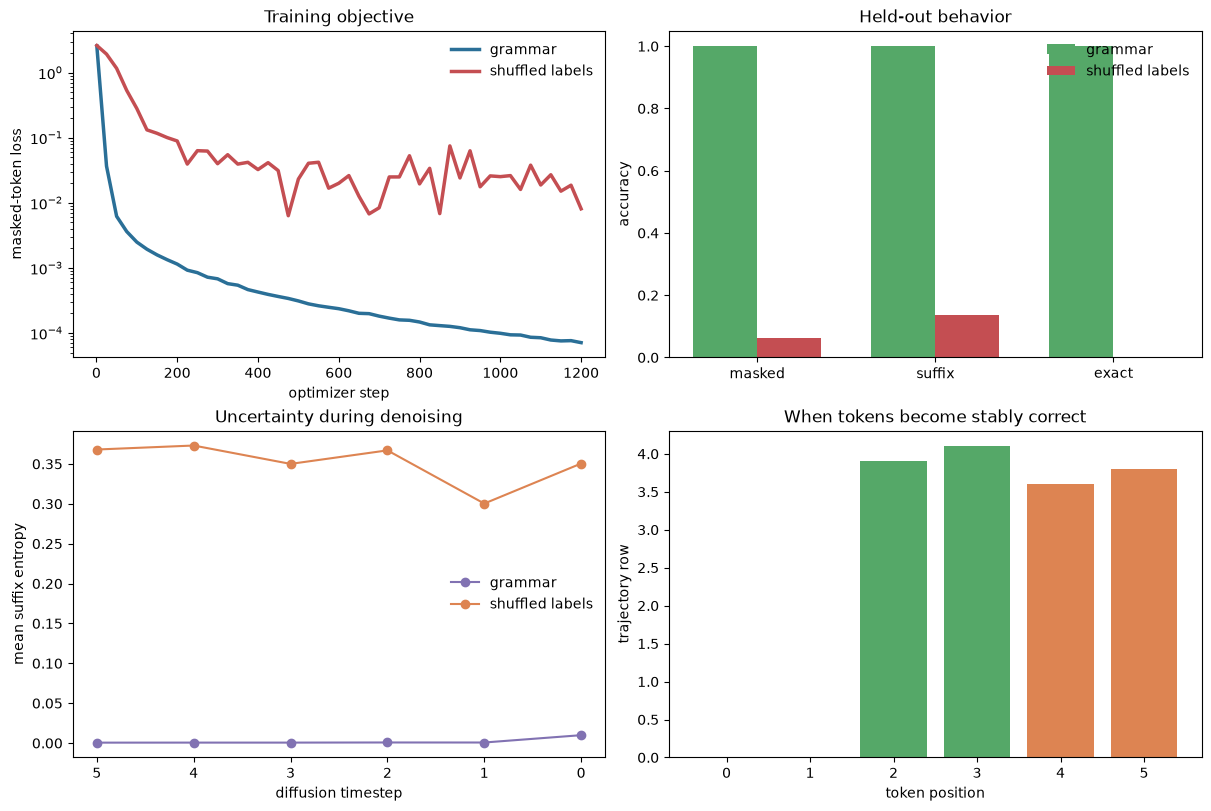
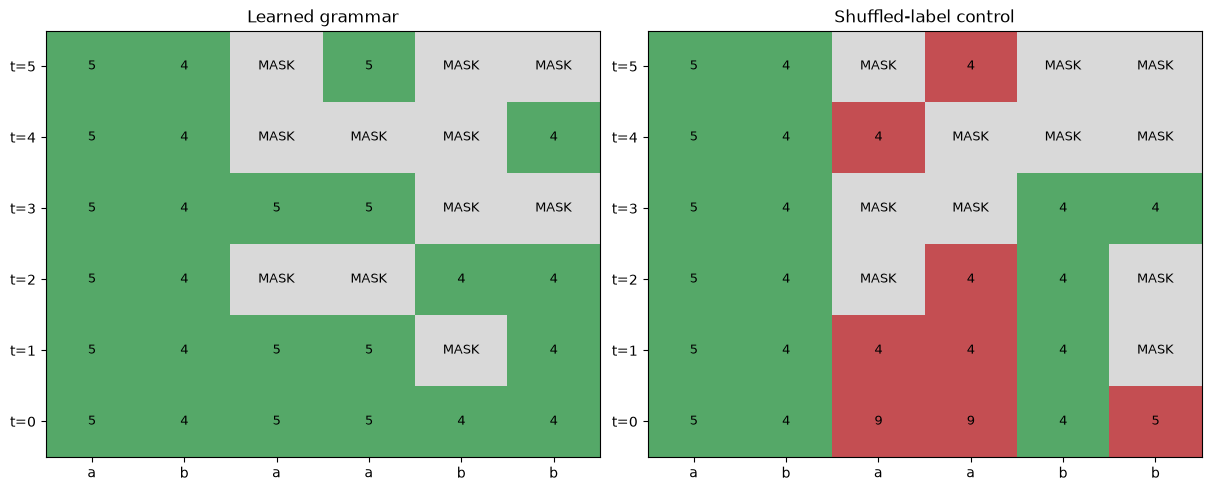

In [ ]:
if RUN_COPY_WARMUP:
    timesteps = list(reversed(range(schedule.num_steps)))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

    axes[0, 0].plot(main_curve["steps"], main_curve["losses"], color="#2a6f97", lw=2.5, label="grammar")
    axes[0, 0].plot(shuffled_curve["steps"], shuffled_curve["losses"], color="#c44e52", lw=2.5, label="shuffled labels")
    axes[0, 0].set_yscale("log")
    axes[0, 0].set(title="Training objective", xlabel="optimizer step", ylabel="masked-token loss")
    axes[0, 0].legend(frameon=False)

    x = np.arange(len(metrics))
    axes[0, 1].bar(x - 0.18, metrics["trained grammar"], 0.36, color="#55a868", label="grammar")
    axes[0, 1].bar(x + 0.18, metrics["shuffled-label training"], 0.36, color="#c44e52", label="shuffled labels")
    axes[0, 1].set_ylim(0, 1.05)
    axes[0, 1].set_xticks(x, ["masked", "suffix", "exact"])
    axes[0, 1].set(title="Held-out behavior", ylabel="accuracy")
    axes[0, 1].legend(frameon=False)

    axes[1, 0].plot(timesteps, main_result["entropy"], marker="o", color="#8172b2", label="grammar")
    axes[1, 0].plot(timesteps, shuffled_result["entropy"], marker="o", color="#dd8452", label="shuffled labels")
    axes[1, 0].invert_xaxis()
    axes[1, 0].set(title="Uncertainty during denoising", xlabel="diffusion timestep", ylabel="mean suffix entropy")
    axes[1, 0].legend(frameon=False)

    positions = np.arange(6)
    commitment = main_result["stable_commitment"].float().mean(0).cpu()
    axes[1, 1].bar(positions, commitment, color=["#4c72b0", "#4c72b0", "#55a868", "#55a868", "#dd8452", "#dd8452"])
    axes[1, 1].set_xticks(positions)
    axes[1, 1].set(title="When tokens become stably correct", xlabel="token position", ylabel="trajectory row")
    fig.savefig(assets_dir / "diffusion_copy_controls.png", dpi=150)
    plt.show()


    def trajectory_panel(ax, trajectory, target, title):
        target = target.cpu()
        trajectory = trajectory.cpu()
        state = t.where(
            trajectory.eq(schedule.mask_token_id),
            0,
            t.where(trajectory.eq(target[None, :]), 2, 1),
        )
        ax.imshow(state, cmap=ListedColormap(["#d9d9d9", "#c44e52", "#55a868"]), vmin=0, vmax=2, aspect="auto")
        for row in range(trajectory.shape[0]):
            for col in range(trajectory.shape[1]):
                token = "MASK" if trajectory[row, col] == schedule.mask_token_id else str(int(trajectory[row, col]))
                ax.text(col, row, token, ha="center", va="center", fontsize=9)
        ax.set_xticks(range(6), ["a", "b", "a", "a", "b", "b"])
        ax.set_yticks(range(6), [f"t={x}" for x in timesteps])
        ax.set_title(title)

    example = 0
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
    trajectory_panel(axes[0], main_result["trajectory"][:, example], heldout_tokens[example], "Learned grammar")
    trajectory_panel(axes[1], shuffled_result["trajectory"][:, example], heldout_tokens[example], "Shuffled-label control")
    fig.savefig(assets_dir / "diffusion_copy_trajectory.png", dpi=150)
    plt.show()

    rows = []
    for row, timestep in enumerate(timesteps):
        rows.append({
            "timestep": timestep,
            "grammar trajectory": ["MASK" if x == 10 else int(x) for x in main_result["trajectory"][row, example].tolist()],
            "shuffled trajectory": ["MASK" if x == 10 else int(x) for x in shuffled_result["trajectory"][row, example].tolist()],
        })
    display(pd.DataFrame(rows))
    print("target:", heldout_tokens[example].tolist())

![Training, controls, entropy, and stable commitment](../../instructions/assets/diffusion_lm_signature_metrics.png)

![Learned and shuffled-label denoising trajectories](../../instructions/assets/diffusion_lm_signature_trajectories.png)

<details><summary>Interpretation</summary>

The main model reaches exact held-out reconstruction because the suffix is a deterministic function of the visible prefix. Its loss curve alone does not establish this: the shuffled-label model can also reduce its training objective by memorizing arbitrary training associations. The decisive evidence is held-out iterative sampling, where the real grammar generalizes and the shuffled control does not.

The trajectory heatmaps add mechanism-level intuition. Gray cells are still masked, red cells are visible but wrong, and green cells equal the ground-truth token. Stable commitment is measured only when a token remains correct for all later rows, so temporary guesses do not count.

</details>

## Try It Yourself

Change the prefix, remasking rule, or seed. Predict which suffix positions will stabilize first, then rerun the cell. Uniform remasking has the same mask budget but ignores confidence; treat its result as a baseline and only call it a failed control if the measured metrics actually deteriorate.

In [ ]:
if RUN_COPY_WARMUP:
    # Try It Yourself: change these values, then rerun this cell.
    play_a, play_b = 8, 1
    play_remask = "confidence"  # compare with "uniform"
    play_seed = 17
    play_target = t.tensor([[play_a, play_b, play_a, play_a, play_b, play_b]], device=device)
    play_generator = t.Generator(device=device).manual_seed(play_seed)
    with t.inference_mode():
        play_output, play_trajectory, play_entropy, _ = conditional_diffusion_sample(
            main_model,
            play_target,
            schedule,
            remask=play_remask,
            generator=play_generator,
        )
    play_rows = []
    for row, timestep in enumerate(timesteps):
        play_rows.append({
            "timestep": timestep,
            "tokens": ["MASK" if x == 10 else int(x) for x in play_trajectory[row, 0].tolist()],
            "mean suffix entropy": play_entropy[row],
        })
    display(pd.DataFrame(play_rows).style.format({"mean suffix entropy": "{:.4f}"}))
    print("target:", play_target[0].tolist())
    print("output:", play_output[0].tolist())

<details><summary>Bonus: anomaly hunting</summary>

- Search all 100 prefixes for the latest stable commitment time.
- Compare confidence and uniform remasking over ten seeds with the same mask budget.
- Increase the number of reverse steps while keeping the trained model fixed.
- Find prefixes where a token becomes correct, is remasked, and later recommits.
- Replace stable commitment with first-visible time and quantify how often the simpler metric lies.

A useful anomaly is reproducible and changes a stated interpretation. A colorful trajectory with no metric or control is not evidence.

</details>

# 2️⃣ Finite text diffusion

## Part B — absorbing diffusion on real token strings

The copy model supplied a timestep embedding and used an iterative remasking
heuristic. Now derive a finite absorbing process. Each clean target token stays
unchanged or becomes MASK; a forward trajectory never returns from MASK.
At level $k$, its masking probability is $p_k=k/T$. The conditioning prefix is
never eligible for corruption.

Every sequence has 40 context slots and 24 target slots. The context contains
BOS, the question, padding and SEP. All 24 target slots are eligible and valid
attention keys, including EOS and any clean PAD fill. At generation time all
24 start as MASK. We never hand the model the answer length through an attention
mask. During training some clean fill tokens can be revealed by noising; that
is part of this declared conditional distribution.

Our second model is a time-independent denoiser: it observes the masked
configuration but receives no timestep embedding. The training bound below is
valid for this parameterization; representing time explicitly is a later ablation.
The tokenizer and data I/O are supplied. You implement the model and method.

In [ ]:
from tokenizers import Tokenizer

from part8_diffusion_language_models import text_data

from part8_diffusion_language_models import text_diffusion_tests as diffusion_checks

from part8_diffusion_language_models import text_model_tests as model_checks

from part8_diffusion_language_models import text_training_tests as training_checks

from part8_diffusion_language_models import text_evaluation_tests as evaluation_checks

from part8_diffusion_language_models.text_data import CONTEXT_SLOTS, TARGET_SLOTS, PAD_ID, MASK_ID, BOS_ID, SEP_ID, EOS_ID

from part8_diffusion_language_models.tensor_plumbing import tensor_digest, prepare_text_tensors

### Exercise 11 — Mask targets without revealing the answer length

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(corrupted, selected)` for integer tokens `(B,L)`, boolean eligibility
`(B,L)` and one probability `(B,)` per example. Draw independent Bernoulli masks
on the token device using the supplied generator. Validate shape, range and
clean-target assumptions. Neither context nor the caller's input may change.

<details><summary>Help — work through the shapes</summary>

Broadcast probabilities along positions. Intersect the random draw with
eligibility before calling `masked_fill`; counting PAD is not an eligibility rule.

</details>

<details><summary>Expected output</summary>

The zero/all-mask endpoints, seeded frequency check and conditioning-preservation checks pass.

</details>

<details><summary>Worked formulation</summary>

```python
def mask_targets(tokens: t.Tensor, eligible: t.Tensor, probability: t.Tensor,
                 mask_id: int, *, generator: t.Generator | None = None):
    """Corrupt eligible positions only, without using target length as a mask."""
    if tokens.ndim != 2 or eligible.shape != tokens.shape or eligible.dtype != t.bool:
        raise ValueError("tokens and boolean eligibility must have shape (batch, positions)")
    if probability.shape != (tokens.shape[0],) or not ((0 <= probability) & (probability <= 1)).all():
        raise ValueError("one probability in [0,1] per example is required")
    if tokens[eligible].eq(mask_id).any():
        raise ValueError("clean targets cannot contain MASK")
    selected = eligible & (t.rand(tokens.shape, device=tokens.device, generator=generator) < probability[:, None])
    return tokens.masked_fill(selected, mask_id), selected
```

</details>

In [ ]:
def mask_targets(tokens: t.Tensor, eligible: t.Tensor, probability: t.Tensor,
                 mask_id: int, *, generator: t.Generator | None = None):
    raise NotImplementedError()

diffusion_checks.test_target_masking(mask_targets)

<details><summary>Solution</summary>

```python
def mask_targets(tokens: t.Tensor, eligible: t.Tensor, probability: t.Tensor,
                 mask_id: int, *, generator: t.Generator | None = None):
    """Corrupt eligible positions only, without using target length as a mask."""
    if tokens.ndim != 2 or eligible.shape != tokens.shape or eligible.dtype != t.bool:
        raise ValueError("tokens and boolean eligibility must have shape (batch, positions)")
    if probability.shape != (tokens.shape[0],) or not ((0 <= probability) & (probability <= 1)).all():
        raise ValueError("one probability in [0,1] per example is required")
    if tokens[eligible].eq(mask_id).any():
        raise ValueError("clean targets cannot contain MASK")
    selected = eligible & (t.rand(tokens.shape, device=tokens.device, generator=generator) < probability[:, None])
    return tokens.masked_fill(selected, mask_id), selected

diffusion_checks.test_target_masking(mask_targets)
```
</details>

### Exercise 12 — Derive the finite variational objective

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 25-35 minutes on this exercise.
> ```

For a masked token at step $k$, the exact posterior reveals its clean value
at step $k-1$ with probability $1/k$. Its conditional KL is therefore clean-token
cross entropy divided by $k$. Sampling $k$ uniformly multiplies this by $T$:

$$\widehat{\mathcal L}=\frac1B\sum_b\frac{1}{|E_b|}\sum_{i\in E_b}
\mathbf1[x_{k,i}=\mathrm{MASK}]\frac{T}{k_b}
[-\log f_\theta(x_k)_{i,x_{0,i}}].$$

At $k=1$ this is the reconstruction term; at $k=T$ the all-mask prior matches
exactly. Visible-token KL is zero because the reverse kernel copies them.
Exclude MASK from the clean vocabulary and normalize by **all eligible slots**,
even on a sampled row with no masked tokens. A zero-mask row contributes a
finite zero loss and zero gradient. This is a finite-step bound, not a claim
that its number is directly comparable with AR perplexity.

<details><summary>Help — work through the shapes</summary>

Set the MASK logit to negative infinity on a copy, then compute clean NLL.
Use `where(masked, nll, 0)` before weighting. Dividing by the random mask count
would change the estimator. The tiny exhaustive oracle enumerates the forward
chain and checks both the scalar bound and every logit derivative.

</details>

<details><summary>Expected output</summary>

The independent forward-chain bound and gradient agree in float64; a no-mask draw remains exactly zero.

</details>

<details><summary>Worked formulation</summary>

```python
def finite_diffusion_loss(logits: t.Tensor, clean: t.Tensor, corrupted: t.Tensor,
                          eligible: t.Tensor, steps: t.Tensor, total_steps: int,
                          mask_id: int):
    """Unbiased single-time estimator of the finite absorbing variational bound.

    At masked x_k, q(x_{k-1}|x_k,x_0) reveals x_0 with probability 1/k.
    Unmasked states are copied exactly and incur zero KL. Averaging uniformly
    sampled k multiplies the conditional KL by T. The k=1 term is reconstruction;
    the all-mask prior at k=T matches exactly. Never divide by sampled mask count.
    """
    if logits.shape[:-1] != clean.shape or corrupted.shape != clean.shape or eligible.shape != clean.shape:
        raise ValueError("token, logit and eligibility shapes disagree")
    if eligible.dtype != t.bool or not eligible.any(dim=-1).all():
        raise ValueError("each example needs a nonempty boolean target region")
    if total_steps < 1 or steps.shape != (clean.shape[0],) or steps.dtype != t.long:
        raise ValueError("steps must be an integer per-example vector")
    if not ((steps >= 1) & (steps <= total_steps)).all():
        raise ValueError("sample k uniformly from 1..T")
    if clean[eligible].eq(mask_id).any() or not t.equal(clean[~eligible], corrupted[~eligible]):
        raise ValueError("clean targets exclude MASK and conditioning must be unchanged")
    if ((corrupted != clean) & (corrupted != mask_id)).any():
        raise ValueError("this objective assumes absorbing MASK corruption")
    clean_logits = logits.clone()
    clean_logits[..., mask_id] = -t.inf
    # Non-target context may itself use MASK as a literal conditioning symbol.
    safe_targets = clean.masked_fill(~eligible, 0)
    safe_targets = safe_targets.masked_fill(~eligible & safe_targets.eq(mask_id), (mask_id + 1) % logits.shape[-1])
    nll = -clean_logits.log_softmax(-1).gather(-1, safe_targets[..., None]).squeeze(-1)
    masked = eligible & corrupted.eq(mask_id)
    weighted = t.where(masked, nll, 0.) * (total_steps / steps.to(logits.dtype))[:, None]
    return (weighted.sum(-1) / eligible.sum(-1)).mean()
```

</details>

In [ ]:
def finite_diffusion_loss(logits: t.Tensor, clean: t.Tensor, corrupted: t.Tensor,
                          eligible: t.Tensor, steps: t.Tensor, total_steps: int,
                          mask_id: int):
    raise NotImplementedError()

diffusion_checks.test_finite_loss_exact_bound_and_gradient(finite_diffusion_loss)

diffusion_checks.test_finite_loss_zero_masks_and_denominator(finite_diffusion_loss)

<details><summary>Solution</summary>

```python
def finite_diffusion_loss(logits: t.Tensor, clean: t.Tensor, corrupted: t.Tensor,
                          eligible: t.Tensor, steps: t.Tensor, total_steps: int,
                          mask_id: int):
    """Unbiased single-time estimator of the finite absorbing variational bound.

    At masked x_k, q(x_{k-1}|x_k,x_0) reveals x_0 with probability 1/k.
    Unmasked states are copied exactly and incur zero KL. Averaging uniformly
    sampled k multiplies the conditional KL by T. The k=1 term is reconstruction;
    the all-mask prior at k=T matches exactly. Never divide by sampled mask count.
    """
    if logits.shape[:-1] != clean.shape or corrupted.shape != clean.shape or eligible.shape != clean.shape:
        raise ValueError("token, logit and eligibility shapes disagree")
    if eligible.dtype != t.bool or not eligible.any(dim=-1).all():
        raise ValueError("each example needs a nonempty boolean target region")
    if total_steps < 1 or steps.shape != (clean.shape[0],) or steps.dtype != t.long:
        raise ValueError("steps must be an integer per-example vector")
    if not ((steps >= 1) & (steps <= total_steps)).all():
        raise ValueError("sample k uniformly from 1..T")
    if clean[eligible].eq(mask_id).any() or not t.equal(clean[~eligible], corrupted[~eligible]):
        raise ValueError("clean targets exclude MASK and conditioning must be unchanged")
    if ((corrupted != clean) & (corrupted != mask_id)).any():
        raise ValueError("this objective assumes absorbing MASK corruption")
    clean_logits = logits.clone()
    clean_logits[..., mask_id] = -t.inf
    # Non-target context may itself use MASK as a literal conditioning symbol.
    safe_targets = clean.masked_fill(~eligible, 0)
    safe_targets = safe_targets.masked_fill(~eligible & safe_targets.eq(mask_id), (mask_id + 1) % logits.shape[-1])
    nll = -clean_logits.log_softmax(-1).gather(-1, safe_targets[..., None]).squeeze(-1)
    masked = eligible & corrupted.eq(mask_id)
    weighted = t.where(masked, nll, 0.) * (total_steps / steps.to(logits.dtype))[:, None]
    return (weighted.sum(-1) / eligible.sum(-1)).mean()

diffusion_checks.test_finite_loss_exact_bound_and_gradient(finite_diffusion_loss)

diffusion_checks.test_finite_loss_zero_masks_and_denominator(finite_diffusion_loss)
```
</details>

### Exercise 13 — Predict clean tokens and normalize the reverse kernel

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-25 minutes on this exercise.
> ```

`clean_prediction_probs` removes MASK, then returns a softmax at temperature
$\tau>0$ or a greedy point mass at $\tau=0$. For a current MASK and noise levels
$0\le p_s\le p_t$, assign clean mass $(1-p_s/p_t)f_\theta$ and MASK mass
$p_s/p_t$. A visible token receives a point mass at its existing value.
Return `(B,L,V)` normalized probabilities; do not mutate the input logits.

<details><summary>Help — work through the shapes</summary>

Write the two cases separately, then select by `current == mask_id`.
The probability of staying MASK is a property of the schedule, not a prediction
from the network. Check $p_s=0$ and $p_s=p_t$ before a general case.

</details>

<details><summary>Expected output</summary>

Greedy/soft draws exclude MASK; the reverse distribution matches the independently constructed Bayes joint.

</details>

<details><summary>Worked formulation</summary>

```python
def clean_prediction_probs(logits: t.Tensor, mask_id: int, temperature: float):
    """Exclude MASK from the clean distribution; temperature zero is greedy."""
    if temperature < 0 or not 0 <= mask_id < logits.shape[-1]:
        raise ValueError("temperature must be nonnegative and MASK must be in the vocabulary")
    clean_logits = logits.clone()
    clean_logits[..., mask_id] = -t.inf
    if temperature == 0:
        return F.one_hot(clean_logits.argmax(-1), logits.shape[-1]).to(logits.dtype)
    return (clean_logits / temperature).softmax(-1)


def absorbing_reverse_probs(clean_probs: t.Tensor, current: t.Tensor,
                            p_t: float, p_s: float, mask_id: int):
    """Exact normalized reverse kernel: clean mass 1-p_s/p_t, MASK mass p_s/p_t."""
    if not 0 <= p_s <= p_t <= 1 or p_t == 0:
        raise ValueError("require 0 <= p_s <= p_t <= 1 and p_t > 0")
    if clean_probs.shape[:-1] != current.shape:
        raise ValueError("probability and token shapes disagree")
    reverse = clean_probs * (1 - p_s/p_t)
    reverse = reverse.clone()
    reverse[..., mask_id] = p_s/p_t
    point_mass = F.one_hot(current, clean_probs.shape[-1]).to(clean_probs.dtype)
    return t.where(current.eq(mask_id)[..., None], reverse, point_mass)
```

</details>

In [ ]:
def clean_prediction_probs(logits: t.Tensor, mask_id: int, temperature: float):
    raise NotImplementedError()

def absorbing_reverse_probs(clean_probs: t.Tensor, current: t.Tensor,
                            p_t: float, p_s: float, mask_id: int):
    raise NotImplementedError()

diffusion_checks.test_clean_distribution(clean_prediction_probs)

diffusion_checks.test_reverse_kernel_matches_bayes(absorbing_reverse_probs)

In [ ]:
def categorical_tokens(probs: t.Tensor, *, generator: t.Generator | None = None):
    return t.multinomial(probs.flatten(0, -2), 1, generator=generator).reshape(probs.shape[:-1])

<details><summary>Solution</summary>

```python
def clean_prediction_probs(logits: t.Tensor, mask_id: int, temperature: float):
    """Exclude MASK from the clean distribution; temperature zero is greedy."""
    if temperature < 0 or not 0 <= mask_id < logits.shape[-1]:
        raise ValueError("temperature must be nonnegative and MASK must be in the vocabulary")
    clean_logits = logits.clone()
    clean_logits[..., mask_id] = -t.inf
    if temperature == 0:
        return F.one_hot(clean_logits.argmax(-1), logits.shape[-1]).to(logits.dtype)
    return (clean_logits / temperature).softmax(-1)

def absorbing_reverse_probs(clean_probs: t.Tensor, current: t.Tensor,
                            p_t: float, p_s: float, mask_id: int):
    """Exact normalized reverse kernel: clean mass 1-p_s/p_t, MASK mass p_s/p_t."""
    if not 0 <= p_s <= p_t <= 1 or p_t == 0:
        raise ValueError("require 0 <= p_s <= p_t <= 1 and p_t > 0")
    if clean_probs.shape[:-1] != current.shape:
        raise ValueError("probability and token shapes disagree")
    reverse = clean_probs * (1 - p_s/p_t)
    reverse = reverse.clone()
    reverse[..., mask_id] = p_s/p_t
    point_mass = F.one_hot(current, clean_probs.shape[-1]).to(clean_probs.dtype)
    return t.where(current.eq(mask_id)[..., None], reverse, point_mass)

diffusion_checks.test_clean_distribution(clean_prediction_probs)

diffusion_checks.test_reverse_kernel_matches_bayes(absorbing_reverse_probs)
```
</details>

### Exercise 14 — Measure uncertainty, commitment and string errors

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-25 minutes on this exercise.
> ```

Implement Shannon entropy in nats with `0 log 0 = 0`; stable commitment from
states `(K,B,L)`; unit-cost insert/delete/substitute edit distance; and a strict
parenthesis grammar checker. Commitment is the first permanent match to the
**final token**, not the first reveal and not evidence that the token is correct.
A final MASK has commitment `-1`. Grammar validity rejects empty strings,
non-parenthesis characters and any prefix with more closes than opens.

<details><summary>Help — work through the shapes</summary>

Find the last state differing from the final state, then add one. A dynamic
program needs only the previous edit-distance row. For parentheses, update a
running balance and fail at its first negative value.

</details>

<details><summary>Expected output</summary>

`kitten → sitting` costs 3 edits; a fixture with a revised token commits later than its first reveal.

</details>

<details><summary>Worked formulation</summary>

```python
def entropy_from_probs(probs: t.Tensor):
    """0 log 0 = 0, including the excluded MASK entry and greedy distributions."""
    return -t.special.xlogy(probs, probs).sum(-1)


def stable_token_commitment(states: t.Tensor, mask_id: int):
    """First state equal to the final token with no later revision; -1 if final MASK."""
    if states.ndim != 3 or not states.shape[0]:
        raise ValueError("states must have shape (steps, batch, positions)")
    different = states.ne(states[-1:])
    index = t.arange(states.shape[0], device=states.device)[:, None, None]
    last_difference = t.where(different, index, -1).amax(0)
    return t.where(states[-1].eq(mask_id), -1, last_difference+1)


def levenshtein_distance(left, right):
    """Unit insert/delete/substitute cost on the declared character or token units."""
    previous = list(range(len(right)+1))
    for i, a in enumerate(left, 1):
        current = [i]
        for j, b in enumerate(right, 1):
            current.append(min(current[-1]+1, previous[j]+1, previous[j-1]+(a != b)))
        previous = current
    return previous[-1]


def balanced_parentheses(text: str):
    """Strict grammar score; non-parenthesis characters and early closing fail."""
    balance = 0
    if not text:
        return False
    for char in text:
        if char not in "()":
            return False
        balance += 1 if char == "(" else -1
        if balance < 0:
            return False
    return balance == 0
```

</details>

In [ ]:
def entropy_from_probs(probs: t.Tensor):
    raise NotImplementedError()

def stable_token_commitment(states: t.Tensor, mask_id: int):
    raise NotImplementedError()

def levenshtein_distance(left, right):
    raise NotImplementedError()

def balanced_parentheses(text: str):
    raise NotImplementedError()

diffusion_checks.test_entropy_and_text_metrics(entropy_from_probs, levenshtein_distance, balanced_parentheses)

diffusion_checks.test_stable_commitment_revisions(stable_token_commitment)

<details><summary>Solution</summary>

```python
def entropy_from_probs(probs: t.Tensor):
    """0 log 0 = 0, including the excluded MASK entry and greedy distributions."""
    return -t.special.xlogy(probs, probs).sum(-1)

def stable_token_commitment(states: t.Tensor, mask_id: int):
    """First state equal to the final token with no later revision; -1 if final MASK."""
    if states.ndim != 3 or not states.shape[0]:
        raise ValueError("states must have shape (steps, batch, positions)")
    different = states.ne(states[-1:])
    index = t.arange(states.shape[0], device=states.device)[:, None, None]
    last_difference = t.where(different, index, -1).amax(0)
    return t.where(states[-1].eq(mask_id), -1, last_difference+1)

def levenshtein_distance(left, right):
    """Unit insert/delete/substitute cost on the declared character or token units."""
    previous = list(range(len(right)+1))
    for i, a in enumerate(left, 1):
        current = [i]
        for j, b in enumerate(right, 1):
            current.append(min(current[-1]+1, previous[j]+1, previous[j-1]+(a != b)))
        previous = current
    return previous[-1]

def balanced_parentheses(text: str):
    """Strict grammar score; non-parenthesis characters and early closing fail."""
    balance = 0
    if not text:
        return False
    for char in text:
        if char not in "()":
            return False
        balance += 1 if char == "(" else -1
        if balance < 0:
            return False
    return balance == 0

diffusion_checks.test_entropy_and_text_metrics(entropy_from_probs, levenshtein_distance, balanced_parentheses)

diffusion_checks.test_stable_commitment_revisions(stable_token_commitment)
```
</details>

### Exercise 15 — Implement three samplers with temperature and blocks

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 30-45 minutes on this exercise.
> ```

Start every eligible slot at MASK. For each block, run the declared number
of reverse steps while fixing earlier completed blocks and keeping future
blocks masked. Ancestral sampling draws from your reverse probabilities.
Uniform and confidence reveal rules instead propose values for currently
masked slots and remask a fixed count `floor(block_width * p_s)` of those proposals.
All three carry visible tokens forward unchanged.

For confidence, retain proposals with the largest **untempered model probability**.
Sampling temperature controls which token is drawn. It must not turn every
confidence into one at greedy temperature zero. Record predictive entropy from
temperature-one probabilities, the pre-step mask, actual input-token work and
states including the initial all-mask state. With trace recording off, keep only
the small workload records and identical token behavior.

<details><summary>Help — work through the shapes</summary>

Give already visible positions infinite retention priority, so they cannot
be chosen for remasking. Their output logits were never supervised by the
masked-only loss. `argsort(stable=True)` makes confidence ties reproducible.
The adversarial oracle deliberately makes those visible-position logits wrong;
another puts the most confident token on the right so a left-to-right fallback fails.

</details>

<details><summary>Expected output</summary>

All three finish without MASK, preserve context/earlier blocks, obey seeded schedules and pass the two adversarial sampler tests.

</details>

<details><summary>Worked formulation</summary>

```python
@t.no_grad()
def sample_text_diffusion(model_fn: Callable, conditioning: t.Tensor, eligible: t.Tensor,
                          mask_id: int, *, steps: int, sampler: str = "ancestral",
                          temperatures: tuple[float, float] = (1., 1.),
                          block_size: int | None = None, generator: t.Generator | None = None,
                          record_trace: bool = True):
    """Generate actual states; fixed earlier blocks and context are never rewritten.

    model_fn(tokens, noise_fraction) returns logits. The model is trained on
    arbitrary masked subsets. Block generation treats completed earlier blocks
    as conditioning; future blocks remain MASK. Confidence/uniform remasking
    fills masked positions and remasks a fixed count of the newly proposed
    tokens. Previously revealed tokens carry over: their prediction logits are
    not supervised by the masked-only objective. The fixed-count rules differ
    from the independent ancestral reverse probabilities.

    Confidence and recorded entropy use the model distribution at temperature
    one. Sampling temperature controls token draws, not the confidence scale;
    otherwise greedy sampling makes every selected probability one and destroys
    the confidence ordering as well as the uncertainty trace.
    """
    if steps < 1 or sampler not in {"ancestral", "confidence", "uniform"}:
        raise ValueError("choose positive steps and an explicit sampler")
    if eligible.shape != conditioning.shape or eligible.dtype != t.bool or conditioning.ndim != 2:
        raise ValueError("conditioning and boolean eligibility must be two-dimensional")
    if not t.equal(eligible, eligible[:1].expand_as(eligible)):
        raise ValueError("this teaching sampler uses the same fixed target slots for every row")
    positions = eligible[0].nonzero().flatten()
    if not len(positions) or min(temperatures) < 0:
        raise ValueError("need target slots and nonnegative temperatures")
    block_size = len(positions) if block_size is None else block_size
    if block_size < 1:
        raise ValueError("block size must be positive")
    tokens = conditioning.masked_fill(eligible, mask_id)
    states = [tokens.detach().clone()] if record_trace else []
    records = []
    for block, active in enumerate(positions.split(block_size)):
        for step in range(steps, 0, -1):
            p_t, p_s = step/steps, (step-1)/steps
            progress = (steps-step)/max(steps-1, 1)
            temperature = temperatures[0] + progress*(temperatures[1]-temperatures[0])
            logits = model_fn(tokens, p_t)
            probabilities = clean_prediction_probs(logits[:, active], mask_id, temperature)
            model_probabilities = clean_prediction_probs(logits[:, active], mask_id, 1.) if (sampler == "confidence" or record_trace) else None
            previous = tokens[:, active].clone()
            if sampler == "ancestral":
                reverse = absorbing_reverse_probs(probabilities, previous, p_t, p_s, mask_id)
                updated = categorical_tokens(reverse, generator=generator)
            else:
                proposed = categorical_tokens(probabilities, generator=generator)
                was_masked = previous.eq(mask_id)
                updated = t.where(was_masked, proposed, previous)
                if sampler == "confidence":
                    priority = model_probabilities.gather(-1, proposed[..., None]).squeeze(-1)
                else:
                    priority = t.rand(updated.shape, device=tokens.device, generator=generator)
                priority = priority.masked_fill(~was_masked, t.inf)
                count = int(len(active)*p_s)
                remasked = priority.argsort(dim=-1, stable=True)[:, :count]
                updated.scatter_(1, remasked, mask_id)
            tokens[:, active] = updated
            record = {"block": block, "p_t": p_t, "p_s": p_s, "temperature": temperature,
                      "model_calls": len(records)+1, "input_tokens": tokens.numel()}
            if record_trace:
                record.update(active_positions=active.detach().clone(),
                    entropy=entropy_from_probs(model_probabilities).detach().clone(),
                    masked_before=previous.eq(mask_id).detach().clone())
                states.append(tokens.detach().clone())
            records.append(record)
    return tokens, t.stack(states) if record_trace else None, records
```

</details>

In [ ]:
@t.no_grad()
def sample_text_diffusion(model_fn: Callable, conditioning: t.Tensor, eligible: t.Tensor,
                          mask_id: int, *, steps: int, sampler: str = "ancestral",
                          temperatures: tuple[float, float] = (1., 1.),
                          block_size: int | None = None, generator: t.Generator | None = None,
                          record_trace: bool = True):
    raise NotImplementedError()

diffusion_checks.test_diffusion_sampler_context_and_block_semantics(sample_text_diffusion)

diffusion_checks.test_sampler_temperature_schedule_and_seed(sample_text_diffusion)

diffusion_checks.test_remasking_never_uses_unsupervised_visible_token_logits(sample_text_diffusion)

diffusion_checks.test_confidence_and_entropy_survive_greedy_sampling(sample_text_diffusion)

<details><summary>Solution</summary>

```python
@t.no_grad()
def sample_text_diffusion(model_fn: Callable, conditioning: t.Tensor, eligible: t.Tensor,
                          mask_id: int, *, steps: int, sampler: str = "ancestral",
                          temperatures: tuple[float, float] = (1., 1.),
                          block_size: int | None = None, generator: t.Generator | None = None,
                          record_trace: bool = True):
    """Generate actual states; fixed earlier blocks and context are never rewritten.

    model_fn(tokens, noise_fraction) returns logits. The model is trained on
    arbitrary masked subsets. Block generation treats completed earlier blocks
    as conditioning; future blocks remain MASK. Confidence/uniform remasking
    fills masked positions and remasks a fixed count of the newly proposed
    tokens. Previously revealed tokens carry over: their prediction logits are
    not supervised by the masked-only objective. The fixed-count rules differ
    from the independent ancestral reverse probabilities.

    Confidence and recorded entropy use the model distribution at temperature
    one. Sampling temperature controls token draws, not the confidence scale;
    otherwise greedy sampling makes every selected probability one and destroys
    the confidence ordering as well as the uncertainty trace.
    """
    if steps < 1 or sampler not in {"ancestral", "confidence", "uniform"}:
        raise ValueError("choose positive steps and an explicit sampler")
    if eligible.shape != conditioning.shape or eligible.dtype != t.bool or conditioning.ndim != 2:
        raise ValueError("conditioning and boolean eligibility must be two-dimensional")
    if not t.equal(eligible, eligible[:1].expand_as(eligible)):
        raise ValueError("this teaching sampler uses the same fixed target slots for every row")
    positions = eligible[0].nonzero().flatten()
    if not len(positions) or min(temperatures) < 0:
        raise ValueError("need target slots and nonnegative temperatures")
    block_size = len(positions) if block_size is None else block_size
    if block_size < 1:
        raise ValueError("block size must be positive")
    tokens = conditioning.masked_fill(eligible, mask_id)
    states = [tokens.detach().clone()] if record_trace else []
    records = []
    for block, active in enumerate(positions.split(block_size)):
        for step in range(steps, 0, -1):
            p_t, p_s = step/steps, (step-1)/steps
            progress = (steps-step)/max(steps-1, 1)
            temperature = temperatures[0] + progress*(temperatures[1]-temperatures[0])
            logits = model_fn(tokens, p_t)
            probabilities = clean_prediction_probs(logits[:, active], mask_id, temperature)
            model_probabilities = clean_prediction_probs(logits[:, active], mask_id, 1.) if (sampler == "confidence" or record_trace) else None
            previous = tokens[:, active].clone()
            if sampler == "ancestral":
                reverse = absorbing_reverse_probs(probabilities, previous, p_t, p_s, mask_id)
                updated = categorical_tokens(reverse, generator=generator)
            else:
                proposed = categorical_tokens(probabilities, generator=generator)
                was_masked = previous.eq(mask_id)
                updated = t.where(was_masked, proposed, previous)
                if sampler == "confidence":
                    priority = model_probabilities.gather(-1, proposed[..., None]).squeeze(-1)
                else:
                    priority = t.rand(updated.shape, device=tokens.device, generator=generator)
                priority = priority.masked_fill(~was_masked, t.inf)
                count = int(len(active)*p_s)
                remasked = priority.argsort(dim=-1, stable=True)[:, :count]
                updated.scatter_(1, remasked, mask_id)
            tokens[:, active] = updated
            record = {"block": block, "p_t": p_t, "p_s": p_s, "temperature": temperature,
                      "model_calls": len(records)+1, "input_tokens": tokens.numel()}
            if record_trace:
                record.update(active_positions=active.detach().clone(),
                    entropy=entropy_from_probs(model_probabilities).detach().clone(),
                    masked_before=previous.eq(mask_id).detach().clone())
                states.append(tokens.detach().clone())
            records.append(record)
    return tokens, t.stack(states) if record_trace else None, records

diffusion_checks.test_diffusion_sampler_context_and_block_semantics(sample_text_diffusion)

diffusion_checks.test_sampler_temperature_schedule_and_seed(sample_text_diffusion)

diffusion_checks.test_remasking_never_uses_unsupervised_visible_token_logits(sample_text_diffusion)

diffusion_checks.test_confidence_and_entropy_survive_greedy_sampling(sample_text_diffusion)
```
</details>

### Read the schedules before training

An absorbing reveal is irreversible. Increasing the number of steps changes
which partial contexts the model sees; it does not grant permission to repair
an already committed mistake. Fixed-count confidence and uniform reveal rules
are useful alternatives but are not independent draws from the ancestral
kernel. Their exact mask counts can differ visibly. At greedy temperature,
the token draw is deterministic conditional on logits, while the model's
predictive entropy can still be large.

### Exercise 16 — Build attention that supports both experiments

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 25-35 minutes on this exercise.
> ```

Implement QKV projections, head reshaping and the full key-validity mask.
Bidirectional attention uses every valid key. Causal attention also requires
`key_position <= query_position`. A cache concatenates old K,V along the key
sequence and offsets current query positions by its length. Reject a cached
bidirectional pass: newly revealed future tokens invalidate earlier keys/values.
Return `(output, (keys, values))` with projected output `(B,L,D)`.
Use attributes `heads`, `qkv` and `output` so the explicit-head oracle can inspect them.

<details><summary>Help — work through the shapes</summary>

QKV can be reshaped to `(B,L,3,H,D/H)` and permuted to `(3,B,H,L,D/H)`.
`scaled_dot_product_attention` accepts a boolean mask whose True entries are
allowed. During cached decoding, validity describes all old and new keys.

</details>

<details><summary>Expected output</summary>

Both masks agree with explicit per-head sums and independent gradients in float64.

</details>

<details><summary>Worked formulation</summary>

```python
class TextAttention(nn.Module):
    def __init__(self, width: int, heads: int):
        super().__init__()
        if width % heads:
            raise ValueError('width must be divisible by heads')
        self.heads = heads
        self.qkv = nn.Linear(width, 3*width)
        self.output = nn.Linear(width, width)

    def forward(self, hidden, valid, *, causal: bool, cache=None):
        batch, length, width = hidden.shape
        q, k, v = self.qkv(hidden).reshape(batch,length,3,self.heads,width//self.heads).permute(2,0,3,1,4)
        past = 0 if cache is None else cache[0].shape[-2]
        if cache is not None:
            if not causal:
                raise ValueError('a bidirectional pass cannot append to a stale KV cache')
            k = t.cat((cache[0],k),dim=-2)
            v = t.cat((cache[1],v),dim=-2)
        if valid.dtype != t.bool or valid.shape != (batch,past+length) or not valid.any(-1).all():
            raise ValueError('valid must describe every existing and current key')
        mask = valid[:,None,None,:]
        if causal:
            query_position = past+t.arange(length,device=hidden.device)
            key_position = t.arange(past+length,device=hidden.device)
            mask = mask & (key_position[None,:] <= query_position[:,None])[None,None]
        attended = F.scaled_dot_product_attention(q,k,v,attn_mask=mask,dropout_p=0.)
        out = attended.transpose(1,2).reshape(batch,length,width)
        return self.output(out), (k,v)
```

</details>

In [ ]:
class TextAttention(nn.Module):
    raise NotImplementedError()

model_checks.test_attention_value_and_gradient(TextAttention)

<details><summary>Solution</summary>

```python
class TextAttention(nn.Module):
    def __init__(self, width: int, heads: int):
        super().__init__()
        if width % heads:
            raise ValueError('width must be divisible by heads')
        self.heads = heads
        self.qkv = nn.Linear(width, 3*width)
        self.output = nn.Linear(width, width)

    def forward(self, hidden, valid, *, causal: bool, cache=None):
        batch, length, width = hidden.shape
        q, k, v = self.qkv(hidden).reshape(batch,length,3,self.heads,width//self.heads).permute(2,0,3,1,4)
        past = 0 if cache is None else cache[0].shape[-2]
        if cache is not None:
            if not causal:
                raise ValueError('a bidirectional pass cannot append to a stale KV cache')
            k = t.cat((cache[0],k),dim=-2)
            v = t.cat((cache[1],v),dim=-2)
        if valid.dtype != t.bool or valid.shape != (batch,past+length) or not valid.any(-1).all():
            raise ValueError('valid must describe every existing and current key')
        mask = valid[:,None,None,:]
        if causal:
            query_position = past+t.arange(length,device=hidden.device)
            key_position = t.arange(past+length,device=hidden.device)
            mask = mask & (key_position[None,:] <= query_position[:,None])[None,None]
        attended = F.scaled_dot_product_attention(q,k,v,attn_mask=mask,dropout_p=0.)
        out = attended.transpose(1,2).reshape(batch,length,width)
        return self.output(out), (k,v)

model_checks.test_attention_value_and_gradient(TextAttention)
```
</details>

### Exercise 17 — Assemble a parameter-matched Transformer

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-25 minutes on this exercise.
> ```

Build a pre-LayerNorm attention residual and GELU MLP residual with expansion
factor four. Add learned token and absolute-position embeddings, a final
LayerNorm and an untied vocabulary projection. Pass one cache entry per block;
offset positions during cached decoding. The `causal` argument changes the
attention mask, not the architecture or parameter count. Use the attribute
names in the supplied signatures/solution for inspection and checkpoint exchange.

<details><summary>Help — work through the shapes</summary>

The cache contains attention keys/values, not earlier residual streams.
Create `blocks` as a ModuleList so optimizer parameters are registered. The
test splits one sequence into chunks of unequal length and compares all logits.

</details>

<details><summary>Expected output</summary>

Cached chunks match a full causal pass; changing a future token leaves earlier causal logits exactly unchanged.

</details>

<details><summary>Worked formulation</summary>

```python
class TextBlock(nn.Module):
    def __init__(self, width: int, heads: int):
        super().__init__()
        self.norm_attention = nn.LayerNorm(width)
        self.attention = TextAttention(width,heads)
        self.norm_mlp = nn.LayerNorm(width)
        self.up = nn.Linear(width,4*width)
        self.down = nn.Linear(4*width,width)

    def forward(self, hidden, valid, *, causal: bool, cache=None):
        attention, new_cache = self.attention(self.norm_attention(hidden),valid,causal=causal,cache=cache)
        hidden = hidden+attention
        hidden = hidden+self.down(F.gelu(self.up(self.norm_mlp(hidden))))
        return hidden,new_cache


class TextTransformer(nn.Module):
    def __init__(self, vocabulary: int, *, width: int = 96, heads: int = 4,
                 layers: int = 3, max_length: int = 64):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary,width)
        self.position_embedding = nn.Embedding(max_length,width)
        self.blocks = nn.ModuleList([TextBlock(width,heads) for _ in range(layers)])
        self.final_norm = nn.LayerNorm(width)
        self.unembed = nn.Linear(width,vocabulary)

    def forward(self, tokens, valid, *, causal: bool, cache=None):
        if cache is not None and (not causal or len(cache) != len(self.blocks)):
            raise ValueError('only a complete causal cache can be extended')
        past = 0 if cache is None else cache[0][0].shape[-2]
        if past+tokens.shape[1] > self.position_embedding.num_embeddings:
            raise ValueError('context exceeds the declared positional budget')
        positions = t.arange(past,past+tokens.shape[1],device=tokens.device)
        hidden = self.token_embedding(tokens)+self.position_embedding(positions)
        new_cache = []
        for i,block in enumerate(self.blocks):
            hidden,entry = block(hidden,valid,causal=causal,cache=None if cache is None else cache[i])
            new_cache.append(entry)
        return self.unembed(self.final_norm(hidden)), new_cache if causal else None
```

</details>

In [ ]:
class TextBlock(nn.Module):
    raise NotImplementedError()

class TextTransformer(nn.Module):
    raise NotImplementedError()

model_checks.test_transformer_cache_and_causal_mask(TextTransformer)

<details><summary>Solution</summary>

```python
class TextBlock(nn.Module):
    def __init__(self, width: int, heads: int):
        super().__init__()
        self.norm_attention = nn.LayerNorm(width)
        self.attention = TextAttention(width,heads)
        self.norm_mlp = nn.LayerNorm(width)
        self.up = nn.Linear(width,4*width)
        self.down = nn.Linear(4*width,width)

    def forward(self, hidden, valid, *, causal: bool, cache=None):
        attention, new_cache = self.attention(self.norm_attention(hidden),valid,causal=causal,cache=cache)
        hidden = hidden+attention
        hidden = hidden+self.down(F.gelu(self.up(self.norm_mlp(hidden))))
        return hidden,new_cache

class TextTransformer(nn.Module):
    def __init__(self, vocabulary: int, *, width: int = 96, heads: int = 4,
                 layers: int = 3, max_length: int = 64):
        super().__init__()
        self.token_embedding = nn.Embedding(vocabulary,width)
        self.position_embedding = nn.Embedding(max_length,width)
        self.blocks = nn.ModuleList([TextBlock(width,heads) for _ in range(layers)])
        self.final_norm = nn.LayerNorm(width)
        self.unembed = nn.Linear(width,vocabulary)

    def forward(self, tokens, valid, *, causal: bool, cache=None):
        if cache is not None and (not causal or len(cache) != len(self.blocks)):
            raise ValueError('only a complete causal cache can be extended')
        past = 0 if cache is None else cache[0][0].shape[-2]
        if past+tokens.shape[1] > self.position_embedding.num_embeddings:
            raise ValueError('context exceeds the declared positional budget')
        positions = t.arange(past,past+tokens.shape[1],device=tokens.device)
        hidden = self.token_embedding(tokens)+self.position_embedding(positions)
        new_cache = []
        for i,block in enumerate(self.blocks):
            hidden,entry = block(hidden,valid,causal=causal,cache=None if cache is None else cache[i])
            new_cache.append(entry)
        return self.unembed(self.final_norm(hidden)), new_cache if causal else None

model_checks.test_transformer_cache_and_causal_mask(TextTransformer)
```
</details>

### Exercise 18 — Write the shifted autoregressive loss

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

A logit at position `j-1` predicts target token `j`. Exclude MASK from the
output vocabulary and average NLL over each example's fixed eligible targets,
including EOS/PAD fill. Context positions do not contribute to the objective.
The final input-position logits have no next target in this tensor.

<details><summary>Help — work through the shapes</summary>

Align `logits[:, :-1]`, `sequence[:, 1:]` and `eligible[:, 1:]`. Keep the
per-example denominator before averaging across examples. Verify gradients,
not just a single scalar value.

</details>

<details><summary>Expected output</summary>

Shifted values and gradients match the explicit position-by-position objective.

</details>

<details><summary>Worked formulation</summary>

```python
def autoregressive_target_loss(logits, sequence, eligible, mask_id: int):
    """Predict token j from logits at j-1 and average only the fixed target slots."""
    if logits.shape[:-1] != sequence.shape or eligible.shape != sequence.shape or eligible.dtype != t.bool:
        raise ValueError('logits, sequence and boolean target mask shapes disagree')
    if eligible[:,0].any() or not eligible.any(-1).all():
        raise ValueError('each example needs predicted targets after a context token')
    prediction = logits[:,:-1].clone()
    prediction[...,mask_id] = -t.inf
    selected = eligible[:,1:]
    targets = sequence[:,1:].masked_fill(~selected,(mask_id+1) % logits.shape[-1])
    loss = -prediction.log_softmax(-1).gather(-1,targets[...,None]).squeeze(-1)
    return (t.where(selected,loss,0.).sum(-1)/selected.sum(-1)).mean()
```

</details>

In [ ]:
def autoregressive_target_loss(logits, sequence, eligible, mask_id: int):
    raise NotImplementedError()

model_checks.test_ar_loss_shift_and_gradient(autoregressive_target_loss)

<details><summary>Solution</summary>

```python
def autoregressive_target_loss(logits, sequence, eligible, mask_id: int):
    """Predict token j from logits at j-1 and average only the fixed target slots."""
    if logits.shape[:-1] != sequence.shape or eligible.shape != sequence.shape or eligible.dtype != t.bool:
        raise ValueError('logits, sequence and boolean target mask shapes disagree')
    if eligible[:,0].any() or not eligible.any(-1).all():
        raise ValueError('each example needs predicted targets after a context token')
    prediction = logits[:,:-1].clone()
    prediction[...,mask_id] = -t.inf
    selected = eligible[:,1:]
    targets = sequence[:,1:].masked_fill(~selected,(mask_id+1) % logits.shape[-1])
    loss = -prediction.log_softmax(-1).gather(-1,targets[...,None]).squeeze(-1)
    return (t.where(selected,loss,0.).sum(-1)/selected.sum(-1)).mean()

model_checks.test_ar_loss_shift_and_gradient(autoregressive_target_loss)
```
</details>

### Exercise 19 — Generate causally with per-example EOS and a cache

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 25-35 minutes on this exercise.
> ```

Run a full context prefill and then one input token per cached step. Also
support an uncached path for parity checks. Every row stops at its own EOS;
fill its remaining output with PAD, while other rows may continue. Count the
actual batch forward calls and input tokens. Restore the caller's model mode.
As for diffusion, recorded entropy is predictive uncertainty at temperature one,
even when token draws are greedy. Disable trace storage for fair latency.

<details><summary>Help — work through the shapes</summary>

Track a boolean `finished` vector and record its pre-update value. Stop the
loop only when all rows are finished. Validity grows by one column each step;
the causal cache avoids recomputing earlier positions, not the new-token work.

</details>

<details><summary>Expected output</summary>

Cached/uncached tokens match, the cache reduces input work, different EOS times are retained and greedy entropy is nonzero.

</details>

<details><summary>Worked formulation</summary>

```python
@t.no_grad()
def sample_autoregressive(model, context, valid, *, output_length: int,
                          mask_id: int, eos_id: int, pad_id: int, temperature: float = 1.,
                          use_cache: bool = True, generator: t.Generator | None = None,
                          record_trace: bool = True):
    """Cached/uncached generation with individual EOS, retaining actual cost and tokens."""
    if output_length < 1 or context.shape != valid.shape:
        raise ValueError('need positive output length and context validity')
    tokens = context.clone()
    keys_valid = valid.clone()
    generated = t.full((len(tokens),output_length),pad_id,device=tokens.device,dtype=tokens.dtype)
    finished = t.zeros(len(tokens),device=tokens.device,dtype=t.bool)
    lengths = t.full((len(tokens),),output_length,device=tokens.device,dtype=t.long)
    cache = None
    records = []
    was_training = model.training
    model.eval()
    try:
        for step in range(output_length):
            current = tokens[:,-1:] if use_cache and cache is not None else tokens
            logits,new_cache = model(current,keys_valid,causal=True,cache=cache if use_cache else None)
            if use_cache:
                cache = new_cache
            probabilities = clean_prediction_probs(logits[:,-1],mask_id,temperature)
            sampled = categorical_tokens(probabilities,generator=generator)
            sampled = t.where(finished,pad_id,sampled)
            generated[:,step] = sampled
            newly_finished = ~finished & sampled.eq(eos_id)
            lengths[newly_finished] = step+1
            record = {'model_calls':step+1,'input_tokens':current.numel()}
            if record_trace:
                record.update(entropy=entropy_from_probs(clean_prediction_probs(logits[:,-1],mask_id,1.)).detach(),active=(~finished).clone())
            records.append(record)
            finished |= newly_finished
            tokens = t.cat((tokens,sampled[:,None]),dim=1)
            keys_valid = t.cat((keys_valid,t.ones_like(sampled[:,None],dtype=t.bool)),dim=1)
            if finished.all():
                break
    finally:
        model.train(was_training)
    return generated,lengths,records
```

</details>

In [ ]:
@t.no_grad()
def sample_autoregressive(model, context, valid, *, output_length: int,
                          mask_id: int, eos_id: int, pad_id: int, temperature: float = 1.,
                          use_cache: bool = True, generator: t.Generator | None = None,
                          record_trace: bool = True):
    raise NotImplementedError()

model_checks.test_ar_cached_uncached_generations(sample_autoregressive)

model_checks.test_ar_individual_eos(sample_autoregressive)

model_checks.test_greedy_ar_records_model_entropy(sample_autoregressive)

<details><summary>Solution</summary>

```python
@t.no_grad()
def sample_autoregressive(model, context, valid, *, output_length: int,
                          mask_id: int, eos_id: int, pad_id: int, temperature: float = 1.,
                          use_cache: bool = True, generator: t.Generator | None = None,
                          record_trace: bool = True):
    """Cached/uncached generation with individual EOS, retaining actual cost and tokens."""
    if output_length < 1 or context.shape != valid.shape:
        raise ValueError('need positive output length and context validity')
    tokens = context.clone()
    keys_valid = valid.clone()
    generated = t.full((len(tokens),output_length),pad_id,device=tokens.device,dtype=tokens.dtype)
    finished = t.zeros(len(tokens),device=tokens.device,dtype=t.bool)
    lengths = t.full((len(tokens),),output_length,device=tokens.device,dtype=t.long)
    cache = None
    records = []
    was_training = model.training
    model.eval()
    try:
        for step in range(output_length):
            current = tokens[:,-1:] if use_cache and cache is not None else tokens
            logits,new_cache = model(current,keys_valid,causal=True,cache=cache if use_cache else None)
            if use_cache:
                cache = new_cache
            probabilities = clean_prediction_probs(logits[:,-1],mask_id,temperature)
            sampled = categorical_tokens(probabilities,generator=generator)
            sampled = t.where(finished,pad_id,sampled)
            generated[:,step] = sampled
            newly_finished = ~finished & sampled.eq(eos_id)
            lengths[newly_finished] = step+1
            record = {'model_calls':step+1,'input_tokens':current.numel()}
            if record_trace:
                record.update(entropy=entropy_from_probs(clean_prediction_probs(logits[:,-1],mask_id,1.)).detach(),active=(~finished).clone())
            records.append(record)
            finished |= newly_finished
            tokens = t.cat((tokens,sampled[:,None]),dim=1)
            keys_valid = t.cat((keys_valid,t.ones_like(sampled[:,None],dtype=t.bool)),dim=1)
            if finished.all():
                break
    finally:
        model.train(was_training)
    return generated,lengths,records

model_checks.test_ar_cached_uncached_generations(sample_autoregressive)

model_checks.test_ar_individual_eos(sample_autoregressive)

model_checks.test_greedy_ar_records_model_entropy(sample_autoregressive)
```
</details>

### Exercise 20 — Construct matched controls and fixed development noise

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-25 minutes on this exercise.
> ```

Shuffle complete target strings with one full permutation inside each task.
Keep all fixed points; rejecting them would change the declared control.
Contexts stay attached to their original rows. For development, repeat every
example three times, sample discrete noise times and masks with an independent
generator seeded 1729, and reuse these draws across checkpoints and seeds.

<details><summary>Help — work through the shapes</summary>

Use a separate generator for each source of randomness. A shared global
generator can accidentally give the AR and diffusion models different training
batches because only diffusion consumes noising draws.

</details>

<details><summary>Expected output</summary>

Complete target multisets remain intact within each task; development draws match an independent RNG oracle.

</details>

<details><summary>Worked formulation</summary>

```python
def permute_targets_within_task(sequence, eligible, task_ids, *, generator):
    """One full permutation per task, retaining every draw and any fixed points."""
    if not t.equal(eligible,eligible[:1].expand_as(eligible)):
        raise ValueError('matched controls require identical fixed target slots')
    permutation = t.arange(len(sequence),device=sequence.device)
    for task in task_ids.unique(sorted=True):
        indices = task_ids.eq(task).nonzero().flatten()
        permutation[indices] = indices[t.randperm(len(indices),device=sequence.device,generator=generator)]
    result = t.where(eligible,sequence[permutation],sequence)
    return result,permutation


def fixed_development_noise(development, *, total_steps: int, mask_id: int, repeats: int = 3):
    """Common deterministic Monte Carlo times/masks, independent of training seeds."""
    sequence = development['sequence'].repeat(repeats,1)
    eligible = development['eligible'].repeat(repeats,1)
    generator = t.Generator(device=sequence.device).manual_seed(1729)
    steps = t.randint(1,total_steps+1,(len(sequence),),device=sequence.device,generator=generator)
    noisy,_ = mask_targets(sequence,eligible,steps/total_steps,mask_id,generator=generator)
    return {'sequence':sequence,'eligible':eligible,'valid':development['valid'].repeat(repeats,1),
            'noisy':noisy,'steps':steps}
```

</details>

In [ ]:
def permute_targets_within_task(sequence, eligible, task_ids, *, generator):
    raise NotImplementedError()

def fixed_development_noise(development, *, total_steps: int, mask_id: int, repeats: int = 3):
    raise NotImplementedError()

training_checks.test_shuffle_preserves_context_and_task_marginals(permute_targets_within_task)

training_checks.test_fixed_noise_is_independent_of_training_rng(fixed_development_noise)

<details><summary>Solution</summary>

```python
def permute_targets_within_task(sequence, eligible, task_ids, *, generator):
    """One full permutation per task, retaining every draw and any fixed points."""
    if not t.equal(eligible,eligible[:1].expand_as(eligible)):
        raise ValueError('matched controls require identical fixed target slots')
    permutation = t.arange(len(sequence),device=sequence.device)
    for task in task_ids.unique(sorted=True):
        indices = task_ids.eq(task).nonzero().flatten()
        permutation[indices] = indices[t.randperm(len(indices),device=sequence.device,generator=generator)]
    result = t.where(eligible,sequence[permutation],sequence)
    return result,permutation

def fixed_development_noise(development, *, total_steps: int, mask_id: int, repeats: int = 3):
    """Common deterministic Monte Carlo times/masks, independent of training seeds."""
    sequence = development['sequence'].repeat(repeats,1)
    eligible = development['eligible'].repeat(repeats,1)
    generator = t.Generator(device=sequence.device).manual_seed(1729)
    steps = t.randint(1,total_steps+1,(len(sequence),),device=sequence.device,generator=generator)
    noisy,_ = mask_targets(sequence,eligible,steps/total_steps,mask_id,generator=generator)
    return {'sequence':sequence,'eligible':eligible,'valid':development['valid'].repeat(repeats,1),
            'noisy':noisy,'steps':steps}

training_checks.test_shuffle_preserves_context_and_task_marginals(permute_targets_within_task)

training_checks.test_fixed_noise_is_independent_of_training_rng(fixed_development_noise)
```
</details>

### Evaluate a checkpoint without changing the model

This supplied loop applies your two losses to all development rows. It switches
to evaluation mode, uses no gradients, weights the last short batch correctly
and restores the prior mode. Its role is to compare checkpoints **within** one
objective. The two numerical scales are not a cross-model quality ranking.

In [ ]:
def development_objective(model, development, noise, *, kind: str, total_steps: int,
                          mask_id: int, batch_size: int = 64):
    """Compare checkpoints within one objective; diffusion bound is not AR NLL."""
    source = development if kind=='autoregressive' else noise
    was_training = model.training; model.eval()
    values = []
    try:
        with t.no_grad():
            for start in range(0,len(source['sequence']),batch_size):
                sl = slice(start,start+batch_size)
                if kind=='autoregressive':
                    logits,_ = model(source['sequence'][sl],source['valid'][sl],causal=True)
                    loss = autoregressive_target_loss(logits,source['sequence'][sl],source['eligible'][sl],mask_id)
                else:
                    logits,_ = model(source['noisy'][sl],source['valid'][sl],causal=False)
                    loss = finite_diffusion_loss(logits,source['sequence'][sl],source['noisy'][sl],
                        source['eligible'][sl],source['steps'][sl],total_steps,mask_id)
                values.append((float(loss),len(source['sequence'][sl])))
    finally:
        model.train(was_training)
    return sum(value*count for value,count in values)/sum(count for _,count in values)

### Exercise 21 — Train all four conditions from matched starts

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 35-50 minutes on this exercise.
> ```

Implement equal-per-task minibatches, AdamW, norm clipping at 1 and checkpoint
evaluation at every declared interval. Separate initialization, batch, noise
and target-shuffle RNG streams. Save the earliest checkpoint attaining the
smallest fixed development objective for this model kind, while retaining the
entire history and passing every checkpoint to a saving callback.

Accept train and development bundles only; reject final rows and overlapping
IDs. The returned record must include initialization/batch/noise hashes,
permutation, first two sampled batches, every update loss and checkpoint score.
These make the scientific matching inspectable without hiding training in a utility.

<details><summary>Help — work through the shapes</summary>

Initialize the factory inside `fork_rng`; seed the private batch generator
with `seed+100`, noise with `seed+200` and shuffle with `seed+300`. Clone best
weights to CPU rather than saving references to live parameters. The two-update
oracle independently derives AdamW moments and clipping for both objectives.

</details>

<details><summary>Expected output</summary>

Both optimizers match the independent two-update oracle; all four modes share initial weights and batches; final selection is rejected.

</details>

<details><summary>Worked formulation</summary>

```python
def fit_text_model(factory, training, development, *, kind: str, shuffled: bool,
                   seed: int, mask_id: int, total_steps: int = 16, updates: int = 1500,
                   batch_size: int = 32, learning_rate: float = .002, weight_decay: float = .01,
                   development_every: int = 300, checkpoint_callback=None):
    """Matched batches/initial weights, separate RNG streams and earliest best dev loss.

    No final data is accepted by this API. Every tested checkpoint is retained
    in history; a callback can save each weight snapshot outside the notebook.
    Each task contributes equally to each batch, regardless of corpus size.
    """
    if kind not in {'diffusion','autoregressive'} or updates < 1 or development_every < 1:
        raise ValueError('choose a model objective and positive training budgets')
    if set(training['row_ids']) & set(development['row_ids']):
        raise ValueError('training and development IDs must be disjoint')
    if training['split'] != 'train' or development['split'] != 'development':
        raise ValueError('fitting accepts train and development splits only')
    task_count = len(training['tasks'])
    if batch_size % task_count:
        raise ValueError('batch size must permit equal task contributions')
    device = training['sequence'].device
    gpu_devices = [device.index or 0] if device.type=='cuda' else []
    with t.random.fork_rng(devices=gpu_devices):
        t.manual_seed(seed)
        model = factory().to(device)
    initial_digest = tensor_digest(t.cat([value.detach().flatten() for value in model.parameters()]))
    batch_rng = t.Generator(device=device).manual_seed(seed+100)
    noise_rng = t.Generator(device=device).manual_seed(seed+200)
    shuffle_rng = t.Generator(device=device).manual_seed(seed+300)
    sequence = training['sequence']
    if shuffled:
        sequence,permutation = permute_targets_within_task(sequence,training['eligible'],training['task_ids'],generator=shuffle_rng)
    else:
        permutation = t.arange(len(sequence),device=device)
    groups = [training['task_ids'].eq(index).nonzero().flatten() for index in range(task_count)]
    optimizer = t.optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=weight_decay)
    noise = fixed_development_noise(development,total_steps=total_steps,mask_id=mask_id)
    histories = []; preview = []; batch_hash = hashlib.sha256()
    best_score = float('inf'); best_state = None; best_step = None
    started = time.perf_counter()
    for update in range(1,updates+1):
        model.train()
        indices = t.cat([group[t.randint(len(group),(batch_size//task_count,),device=device,generator=batch_rng)] for group in groups])
        batch_hash.update(indices.detach().cpu().numpy().tobytes())
        clean = sequence[indices]; eligible = training['eligible'][indices]; valid = training['valid'][indices]
        if kind=='diffusion':
            steps = t.randint(1,total_steps+1,(batch_size,),device=device,generator=noise_rng)
            noisy,_ = mask_targets(clean,eligible,steps/total_steps,mask_id,generator=noise_rng)
            logits,_ = model(noisy,valid,causal=False)
            loss = finite_diffusion_loss(logits,clean,noisy,eligible,steps,total_steps,mask_id)
        else:
            steps = None; noisy = clean
            logits,_ = model(clean,valid,causal=True)
            loss = autoregressive_target_loss(logits,clean,eligible,mask_id)
        if not t.isfinite(loss):
            raise ValueError('nonfinite training loss; retain the failed run')
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        norm = t.nn.utils.clip_grad_norm_(model.parameters(),1.)
        optimizer.step()
        if update <= 2:
            preview.append({'indices':indices.detach().cpu().tolist(),'noisy':noisy.detach().cpu().tolist(),
                'steps':None if steps is None else steps.detach().cpu().tolist()})
        histories.append({'step':update,'training_loss':float(loss.detach()),'gradient_norm':float(norm)})
        if update % development_every==0 or update==updates:
            score = development_objective(model,development,noise,kind=kind,total_steps=total_steps,mask_id=mask_id)
            histories[-1]['development_objective'] = score
            if score < best_score:
                best_score = score; best_step = update
                best_state = {name:value.detach().cpu().clone() for name,value in model.state_dict().items()}
            if checkpoint_callback is not None:
                checkpoint_callback(update,model,histories[-1])
    model.load_state_dict(best_state); model.eval()
    record = {'kind':kind,'shuffled':shuffled,'seed':seed,'updates':updates,'batch_size':batch_size,
        'learning_rate':learning_rate,'weight_decay':weight_decay,'gradient_clip':1.,'total_diffusion_steps':total_steps,
        'development_every':development_every,'development_noise_seed':1729,'development_noise_repeats':3,
        'development_steps_sha256':tensor_digest(noise['steps']),'development_noisy_sha256':tensor_digest(noise['noisy']),
        'initial_parameters_sha256':initial_digest,'batch_indices_sha256':batch_hash.hexdigest(),
        'target_permutation':permutation.detach().cpu().tolist(),'preview_batches':preview,'history':histories,
        'selected_step':best_step,'selected_development_objective':best_score,
        'selection_rule':'earliest minimum of the fixed development objective within this model kind',
        'parameter_count':sum(value.numel() for value in model.parameters()),'elapsed_seconds':time.perf_counter()-started}
    return model,record
```

</details>

In [ ]:
def fit_text_model(factory, training, development, *, kind: str, shuffled: bool,
                   seed: int, mask_id: int, total_steps: int = 16, updates: int = 1500,
                   batch_size: int = 32, learning_rate: float = .002, weight_decay: float = .01,
                   development_every: int = 300, checkpoint_callback=None):
    raise NotImplementedError()

training_checks.test_training_matches_two_explicit_adamw_updates(fit_text_model)

training_checks.test_matched_initialization_batches_and_shuffle(fit_text_model)

training_checks.test_final_data_cannot_select_checkpoints(fit_text_model)

<details><summary>Solution</summary>

```python
def fit_text_model(factory, training, development, *, kind: str, shuffled: bool,
                   seed: int, mask_id: int, total_steps: int = 16, updates: int = 1500,
                   batch_size: int = 32, learning_rate: float = .002, weight_decay: float = .01,
                   development_every: int = 300, checkpoint_callback=None):
    """Matched batches/initial weights, separate RNG streams and earliest best dev loss.

    No final data is accepted by this API. Every tested checkpoint is retained
    in history; a callback can save each weight snapshot outside the notebook.
    Each task contributes equally to each batch, regardless of corpus size.
    """
    if kind not in {'diffusion','autoregressive'} or updates < 1 or development_every < 1:
        raise ValueError('choose a model objective and positive training budgets')
    if set(training['row_ids']) & set(development['row_ids']):
        raise ValueError('training and development IDs must be disjoint')
    if training['split'] != 'train' or development['split'] != 'development':
        raise ValueError('fitting accepts train and development splits only')
    task_count = len(training['tasks'])
    if batch_size % task_count:
        raise ValueError('batch size must permit equal task contributions')
    device = training['sequence'].device
    gpu_devices = [device.index or 0] if device.type=='cuda' else []
    with t.random.fork_rng(devices=gpu_devices):
        t.manual_seed(seed)
        model = factory().to(device)
    initial_digest = tensor_digest(t.cat([value.detach().flatten() for value in model.parameters()]))
    batch_rng = t.Generator(device=device).manual_seed(seed+100)
    noise_rng = t.Generator(device=device).manual_seed(seed+200)
    shuffle_rng = t.Generator(device=device).manual_seed(seed+300)
    sequence = training['sequence']
    if shuffled:
        sequence,permutation = permute_targets_within_task(sequence,training['eligible'],training['task_ids'],generator=shuffle_rng)
    else:
        permutation = t.arange(len(sequence),device=device)
    groups = [training['task_ids'].eq(index).nonzero().flatten() for index in range(task_count)]
    optimizer = t.optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=weight_decay)
    noise = fixed_development_noise(development,total_steps=total_steps,mask_id=mask_id)
    histories = []; preview = []; batch_hash = hashlib.sha256()
    best_score = float('inf'); best_state = None; best_step = None
    started = time.perf_counter()
    for update in range(1,updates+1):
        model.train()
        indices = t.cat([group[t.randint(len(group),(batch_size//task_count,),device=device,generator=batch_rng)] for group in groups])
        batch_hash.update(indices.detach().cpu().numpy().tobytes())
        clean = sequence[indices]; eligible = training['eligible'][indices]; valid = training['valid'][indices]
        if kind=='diffusion':
            steps = t.randint(1,total_steps+1,(batch_size,),device=device,generator=noise_rng)
            noisy,_ = mask_targets(clean,eligible,steps/total_steps,mask_id,generator=noise_rng)
            logits,_ = model(noisy,valid,causal=False)
            loss = finite_diffusion_loss(logits,clean,noisy,eligible,steps,total_steps,mask_id)
        else:
            steps = None; noisy = clean
            logits,_ = model(clean,valid,causal=True)
            loss = autoregressive_target_loss(logits,clean,eligible,mask_id)
        if not t.isfinite(loss):
            raise ValueError('nonfinite training loss; retain the failed run')
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        norm = t.nn.utils.clip_grad_norm_(model.parameters(),1.)
        optimizer.step()
        if update <= 2:
            preview.append({'indices':indices.detach().cpu().tolist(),'noisy':noisy.detach().cpu().tolist(),
                'steps':None if steps is None else steps.detach().cpu().tolist()})
        histories.append({'step':update,'training_loss':float(loss.detach()),'gradient_norm':float(norm)})
        if update % development_every==0 or update==updates:
            score = development_objective(model,development,noise,kind=kind,total_steps=total_steps,mask_id=mask_id)
            histories[-1]['development_objective'] = score
            if score < best_score:
                best_score = score; best_step = update
                best_state = {name:value.detach().cpu().clone() for name,value in model.state_dict().items()}
            if checkpoint_callback is not None:
                checkpoint_callback(update,model,histories[-1])
    model.load_state_dict(best_state); model.eval()
    record = {'kind':kind,'shuffled':shuffled,'seed':seed,'updates':updates,'batch_size':batch_size,
        'learning_rate':learning_rate,'weight_decay':weight_decay,'gradient_clip':1.,'total_diffusion_steps':total_steps,
        'development_every':development_every,'development_noise_seed':1729,'development_noise_repeats':3,
        'development_steps_sha256':tensor_digest(noise['steps']),'development_noisy_sha256':tensor_digest(noise['noisy']),
        'initial_parameters_sha256':initial_digest,'batch_indices_sha256':batch_hash.hexdigest(),
        'target_permutation':permutation.detach().cpu().tolist(),'preview_batches':preview,'history':histories,
        'selected_step':best_step,'selected_development_objective':best_score,
        'selection_rule':'earliest minimum of the fixed development objective within this model kind',
        'parameter_count':sum(value.numel() for value in model.parameters()),'elapsed_seconds':time.perf_counter()-started}
    return model,record

training_checks.test_training_matches_two_explicit_adamw_updates(fit_text_model)

training_checks.test_matched_initialization_batches_and_shuffle(fit_text_model)

training_checks.test_final_data_cannot_select_checkpoints(fit_text_model)
```
</details>

### Exercise 22 — Score words without deleting the model’s mistakes

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-25 minutes on this exercise.
> ```

Decode tokens before the first generated EOS, keeping any special-token
mistakes that precede it. Arithmetic and QA require the exact answer plus EOS.
Parentheses additionally have a grammar score: a different valid completion can
be correct. Report token edit distance to the reference separately.
TinyStories has no single correct continuation; do not call reference-token
matching story accuracy. Every prespecified example contributes exactly once.

<details><summary>Help — work through the shapes</summary>

Do not call `decode(..., skip_special_tokens=True)` on malformed outputs.
A PAD before EOS is an error to inspect, not a token to erase. Check IDs and
tasks before aggregating rates so duplicated or missing failures cannot improve them.

</details>

<details><summary>Expected output</summary>

An alternate balanced string is valid despite nonzero edit distance; PAD/MASK mistakes stay visible and missing rows are rejected.

</details>

<details><summary>Worked formulation</summary>

```python
def score_generated_text(row, generated_ids, tokenizer):
    """Keep special-token mistakes visible and require EOS on closed-answer tasks."""
    tokens = list(generated_ids)
    ended = EOS_ID in tokens
    end = tokens.index(EOS_ID) if ended else len(tokens)
    content = tokens[:end]
    # Do not erase invalid PAD, MASK, BOS or SEP predictions before EOS.
    decoded = tokenizer.decode(content,skip_special_tokens=False)
    reference = row['target_ids']
    reference_end = reference.index(EOS_ID) if EOS_ID in reference else len(reference)
    reference_content = reference[:reference_end]
    out = {'id':row['id'],'task':row['task'],'generated_ids':tokens,'text':decoded,
        'eos_seen':ended,'generated_length':end+int(ended),
        'reference_token_edit_distance':levenshtein_distance(content,reference_content),
        'exact_reference_tokens':content==reference_content and (ended or row['task']=='story')}
    if row['task'] in {'qa','arithmetic'}:
        out['exact_answer'] = ended and decoded==row['answer']
    elif row['task']=='parentheses':
        combined = row['parenthesis_prefix']+decoded
        out['grammar_valid'] = ended and len(combined)==2*row['pairs'] and balanced_parentheses(combined)
        out['exact_answer'] = ended and decoded==row['answer']
    return out


def summarize_generated_rows(measured, source_rows):
    """Every prespecified example contributes once; no success-only denominator."""
    expected = {row['id']:row['task'] for row in source_rows}
    if len(measured)!=len(expected) or {row['id'] for row in measured}!=set(expected):
        raise ValueError('retain every generation example exactly once')
    if any(row['task']!=expected[row['id']] for row in measured):
        raise ValueError('score by the task attached to the input ID')
    result = {}
    for task in sorted(set(expected.values())):
        rows = [row for row in measured if row['task']==task]
        values = {'n':len(rows),'eos_rate':sum(row['eos_seen'] for row in rows)/len(rows),
            'mean_reference_token_edit_distance':sum(row['reference_token_edit_distance'] for row in rows)/len(rows),
            'reference_token_match_rate':sum(row['exact_reference_tokens'] for row in rows)/len(rows)}
        if task!='story':
            values['exact_answer_rate'] = sum(row['exact_answer'] for row in rows)/len(rows)
        if task=='parentheses':
            values['valid_grammar_rate'] = sum(row['grammar_valid'] for row in rows)/len(rows)
        result[task] = values
    return result
```

</details>

In [ ]:
def score_generated_text(row, generated_ids, tokenizer):
    raise NotImplementedError()

def summarize_generated_rows(measured, source_rows):
    raise NotImplementedError()

evaluation_checks.test_valid_alternate_grammar_is_not_reference_match(score_generated_text)

evaluation_checks.test_closed_answers_require_eos_and_keep_special_errors(score_generated_text)

evaluation_checks.test_scoring_requires_all_examples_and_no_story_correctness(summarize_generated_rows)

<details><summary>Solution</summary>

```python
def score_generated_text(row, generated_ids, tokenizer):
    """Keep special-token mistakes visible and require EOS on closed-answer tasks."""
    tokens = list(generated_ids)
    ended = EOS_ID in tokens
    end = tokens.index(EOS_ID) if ended else len(tokens)
    content = tokens[:end]
    # Do not erase invalid PAD, MASK, BOS or SEP predictions before EOS.
    decoded = tokenizer.decode(content,skip_special_tokens=False)
    reference = row['target_ids']
    reference_end = reference.index(EOS_ID) if EOS_ID in reference else len(reference)
    reference_content = reference[:reference_end]
    out = {'id':row['id'],'task':row['task'],'generated_ids':tokens,'text':decoded,
        'eos_seen':ended,'generated_length':end+int(ended),
        'reference_token_edit_distance':levenshtein_distance(content,reference_content),
        'exact_reference_tokens':content==reference_content and (ended or row['task']=='story')}
    if row['task'] in {'qa','arithmetic'}:
        out['exact_answer'] = ended and decoded==row['answer']
    elif row['task']=='parentheses':
        combined = row['parenthesis_prefix']+decoded
        out['grammar_valid'] = ended and len(combined)==2*row['pairs'] and balanced_parentheses(combined)
        out['exact_answer'] = ended and decoded==row['answer']
    return out

def summarize_generated_rows(measured, source_rows):
    """Every prespecified example contributes once; no success-only denominator."""
    expected = {row['id']:row['task'] for row in source_rows}
    if len(measured)!=len(expected) or {row['id'] for row in measured}!=set(expected):
        raise ValueError('retain every generation example exactly once')
    if any(row['task']!=expected[row['id']] for row in measured):
        raise ValueError('score by the task attached to the input ID')
    result = {}
    for task in sorted(set(expected.values())):
        rows = [row for row in measured if row['task']==task]
        values = {'n':len(rows),'eos_rate':sum(row['eos_seen'] for row in rows)/len(rows),
            'mean_reference_token_edit_distance':sum(row['reference_token_edit_distance'] for row in rows)/len(rows),
            'reference_token_match_rate':sum(row['exact_reference_tokens'] for row in rows)/len(rows)}
        if task!='story':
            values['exact_answer_rate'] = sum(row['exact_answer'] for row in rows)/len(rows)
        if task=='parentheses':
            values['valid_grammar_rate'] = sum(row['grammar_valid'] for row in rows)/len(rows)
        result[task] = values
    return result

evaluation_checks.test_valid_alternate_grammar_is_not_reference_match(score_generated_text)

evaluation_checks.test_closed_answers_require_eos_and_keep_special_errors(score_generated_text)

evaluation_checks.test_scoring_requires_all_examples_and_no_story_correctness(summarize_generated_rows)
```
</details>

### Generate from the input alone

The input construction below cannot inspect the answer: all target slots begin
masked. The small batching loop calls your samplers and your scorers, records
every generated example, and captures the prespecified trajectory examples.
Read it once, then change a source row's answer in the counterexample test.
The actual model input must remain identical.

In [ ]:
def model_inputs_from_context(rows, device):
    context = t.tensor([row['context_ids'] for row in rows],device=device)
    valid = t.tensor([row['valid'] for row in rows],device=device,dtype=t.bool)
    eligible = t.tensor([row['eligible'] for row in rows],device=device,dtype=t.bool)
    if context.shape[1]!=CONTEXT_SLOTS or not valid[:,CONTEXT_SLOTS:].all():
        raise ValueError('generation uses fixed context and fully valid target slots')
    if eligible[:,:CONTEXT_SLOTS].any() or not eligible[:,CONTEXT_SLOTS:].all():
        raise ValueError('only the fixed target region can be generated')
    conditioning = t.cat((context,t.full((len(rows),TARGET_SLOTS),MASK_ID,device=device,dtype=t.long)),dim=1)
    return context,conditioning,valid,eligible

@t.no_grad()
def generate_text_examples(model, rows, tokenizer, *, kind, seed: int = 0,
                           sampler='confidence', steps: int = 16, temperatures=(0.,0.),
                           block_size=None, batch_size: int = 32, trace_ids=()):
    """Generate from questions alone and score the actual decoded output afterwards."""
    device = next(model.parameters()).device
    generator = t.Generator(device=device).manual_seed(seed)
    measured = []; traces = []; calls = 0
    was_training = model.training;model.eval()
    try:
        for start in range(0,len(rows),batch_size):
            batch = rows[start:start+batch_size]
            context,conditioning,valid,eligible = model_inputs_from_context(batch,device)
            capture = any(row['id'] in trace_ids for row in batch)
            if kind=='autoregressive':
                generated,lengths,records = sample_autoregressive(model,context,valid[:,:CONTEXT_SLOTS],
                    output_length=TARGET_SLOTS,mask_id=MASK_ID,eos_id=EOS_ID,pad_id=PAD_ID,
                    temperature=temperatures[0],generator=generator,record_trace=capture)
                states = None
            elif kind=='diffusion':
                def model_fn(tokens,p_t):return model(tokens,valid,causal=False)[0]
                full,states,records = sample_text_diffusion(model_fn,conditioning,eligible,MASK_ID,
                    steps=steps,sampler=sampler,temperatures=temperatures,block_size=block_size,
                    generator=generator,record_trace=capture)
                generated = full[:,CONTEXT_SLOTS:]
            else:
                raise ValueError('choose autoregressive or diffusion')
            calls += len(records)
            for index,row in enumerate(batch):
                outcome = score_generated_text(row,generated[index].tolist(),tokenizer)
                measured.append(outcome)
                if row['id'] in trace_ids:
                    trace = {'id':row['id'],'kind':kind,'outcome':outcome,'prompt':row['prompt']}
                    if states is not None:
                        trace['states'] = states[:,index,CONTEXT_SLOTS:].tolist()
                        trace['stable_commitment'] = stable_token_commitment(states,MASK_ID)[index,CONTEXT_SLOTS:].tolist()
                    trace['steps'] = [{key:(value[index].tolist() if key in {'entropy','masked_before','active'}
                        else value.tolist() if isinstance(value,t.Tensor) else value)
                        for key,value in record.items()} for record in records]
                    traces.append(trace)
    finally:
        model.train(was_training)
    return {'rows':measured,'summary':summarize_generated_rows(measured,rows),'traces':traces,
            'total_batch_forward_calls':calls,'batch_size':batch_size,'seed':seed,'kind':kind,
            'sampler':sampler if kind=='diffusion' else 'cached AR','steps':steps if kind=='diffusion' else None,
            'temperatures':list(temperatures),'block_size':block_size}

evaluation_checks.test_generation_inputs_ignore_answers_and_target_padding(model_inputs_from_context)

### Exercise 23 — Measure generation cost fairly

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Time the same fixed batch after two warmups and keep five repetitions.
Synchronize CUDA immediately before and after each measured call. Require
identical seeded output tokens and workload on every repetition. Exclude model
loading, training, string decoding and trajectory/entropy storage. Return
latencies alongside actual forward calls, input tokens, batch size and output
slots. AR uses the tested KV cache; diffusion recomputes its bidirectional context.

<details><summary>Help — work through the shapes</summary>

A zero-argument generation closure should recreate its seeded generator
on every call. Compare its output tensor and minimal records. Parallel token
updates alone do not establish a latency advantage over cached AR.

</details>

<details><summary>Expected output</summary>

The timer retains every replicate and rejects both changing outputs and trace overhead.

</details>

<details><summary>Worked formulation</summary>

```python
def measure_generation_latency(generate_fn, *, device, repeats: int = 5, warmups: int = 2):
    """Time identical fixed batches with GPU synchronization and trace storage off.

    The supplied zero-argument function must recreate its seeded generator for
    every call. It returns (generated_tokens, minimal_records). Model loading,
    training and decoding to strings are outside this timer. Actual forward
    calls and input-token counts accompany latency; parallel token generation
    alone is not a speed claim.
    """
    device = t.device(device)
    if repeats < 1 or warmups < 1:
        raise ValueError('at least one warm-up and one measured repeat are required')
    def sync():
        if device.type=='cuda':t.cuda.synchronize(device)
    reference = None; timings=[]; counts=[]
    for iteration in range(warmups+repeats):
        sync();started=time.perf_counter()
        tokens,records = generate_fn()
        sync();elapsed=time.perf_counter()-started
        if reference is None:reference=tokens.detach().clone()
        elif not t.equal(tokens,reference):raise ValueError('timing repeats changed generated tokens or RNG state')
        if any({'entropy','masked_before','active'} & row.keys() for row in records):
            raise ValueError('disable trajectory/entropy storage in both timing paths')
        if iteration>=warmups:
            timings.append(elapsed)
            counts.append({'forward_calls':len(records),'input_tokens':sum(row['input_tokens'] for row in records)})
    if any(row!=counts[0] for row in counts):
        raise ValueError('timing repeats must perform the same workload')
    return {'seconds':timings,'median_seconds':statistics.median(timings),'warmups':warmups,
            'repeats':repeats,**counts[0],'batch_size':len(reference),'output_slots':reference.shape[-1],
            'cuda_synchronized':device.type=='cuda','trajectory_storage':False}
```

</details>

In [ ]:
def measure_generation_latency(generate_fn, *, device, repeats: int = 5, warmups: int = 2):
    raise NotImplementedError()

evaluation_checks.test_latency_repeats_same_tokens_and_rejects_trace_overhead(measure_generation_latency)

<details><summary>Solution</summary>

```python
def measure_generation_latency(generate_fn, *, device, repeats: int = 5, warmups: int = 2):
    """Time identical fixed batches with GPU synchronization and trace storage off.

    The supplied zero-argument function must recreate its seeded generator for
    every call. It returns (generated_tokens, minimal_records). Model loading,
    training and decoding to strings are outside this timer. Actual forward
    calls and input-token counts accompany latency; parallel token generation
    alone is not a speed claim.
    """
    device = t.device(device)
    if repeats < 1 or warmups < 1:
        raise ValueError('at least one warm-up and one measured repeat are required')
    def sync():
        if device.type=='cuda':t.cuda.synchronize(device)
    reference = None; timings=[]; counts=[]
    for iteration in range(warmups+repeats):
        sync();started=time.perf_counter()
        tokens,records = generate_fn()
        sync();elapsed=time.perf_counter()-started
        if reference is None:reference=tokens.detach().clone()
        elif not t.equal(tokens,reference):raise ValueError('timing repeats changed generated tokens or RNG state')
        if any({'entropy','masked_before','active'} & row.keys() for row in records):
            raise ValueError('disable trajectory/entropy storage in both timing paths')
        if iteration>=warmups:
            timings.append(elapsed)
            counts.append({'forward_calls':len(records),'input_tokens':sum(row['input_tokens'] for row in records)})
    if any(row!=counts[0] for row in counts):
        raise ValueError('timing repeats must perform the same workload')
    return {'seconds':timings,'median_seconds':statistics.median(timings),'warmups':warmups,
            'repeats':repeats,**counts[0],'batch_size':len(reference),'output_slots':reference.shape[-1],
            'cuda_synchronized':device.type=='cuda','trajectory_storage':False}

evaluation_checks.test_latency_repeats_same_tokens_and_rejects_trace_overhead(measure_generation_latency)
```
</details>

# 3️⃣ Matched models and measurements

## Part C — freeze the matched study before reading final answers

The training budget is 12,000 updates for every mode, with development checks
every 1,000. We chose this budget using development candidates only. All three
seeds use the same architecture, dataset, minibatch balance and optimizer.
Checkpoint selection minimizes each model kind's own fixed development loss.
Because this can select an early causal checkpoint while diffusion continues
improving, we also evaluate the final-update checkpoints as an explicitly frozen
sensitivity comparison. We do not choose between those two using final results.

The primary comparison uses ancestral diffusion with 16 full-window steps and
greedy token predictions, against cached greedy AR. Every declared diffusion
budget, reveal rule, temperature and block ablation is retained, along with
its matched shuffled model. Untrained models and last-update checkpoints are
evaluated at the primary setting. The final task matrix includes all 128 rows
per task, whether they succeed, generate malformed words, or omit EOS.

The story text comes from pinned source-order subsets. BPE sees only the training
candidate pool. Normalized full-story and actual tokenized-context duplicates
are excluded across splits. The source hashes, chosen IDs, duplicate rejections
and special-token protocol are recorded in the data manifest. Inspect a training
row below before starting the fits.

In [ ]:
import gzip

from part8_diffusion_language_models import text_plotting

def read_verified_split(directory, split, provenance):
    path = directory / f"{split}.json"
    if hashlib.sha256(path.read_bytes()).hexdigest() != provenance["inventory"][split]["sha256"]:
        raise ValueError("Data bytes differ from the pinned inventory")
    return json.loads(path.read_text())

if RUN_TEXT_STUDY:
    data_directory = Path(os.environ.get("ARENA_DIFFUSION_DATA_DIRECTORY", str(output_dir / "data")))
    if not (data_directory / "provenance.json").exists():
        text_data.build_text_data(data_directory)
    data_provenance = json.loads((data_directory / "provenance.json").read_text())
    assert data_provenance["revision"] == text_data.DATASET_REVISION, "Use the pinned TinyStories revision."
    tokenizer_path = data_directory / "tokenizer.json"
    assert hashlib.sha256(tokenizer_path.read_bytes()).hexdigest() == data_provenance["tokenizer_sha256"], "The tokenizer must match training-only provenance."
    tokenizer = Tokenizer.from_file(str(tokenizer_path))
    train_rows = read_verified_split(data_directory, "train", data_provenance)
    development_rows = read_verified_split(data_directory, "development", data_provenance)
    # Final answers have not been loaded by the learner.
    training = prepare_text_tensors(train_rows, device=device)
    development = prepare_text_tensors(development_rows, device=device)
    display(pd.DataFrame([{"task":task,"training":sum(r["task"]==task for r in train_rows),
        "development":sum(r["task"]==task for r in development_rows),"final":128}
        for task in ("parentheses","arithmetic","qa","story")]))
    for task in ("parentheses","arithmetic","qa","story"):
        row = next(r for r in train_rows if r["task"]==task)
        print(task, "INPUT:", row["prompt"], "TARGET:", tokenizer.decode(row["target_ids"], skip_special_tokens=False))

    diffusion_configs = [dict(name=f"{sampler}-{steps}-greedy", sampler=sampler, steps=steps,
        temperatures=[0.,0.], block_size=None)
        for sampler in ("ancestral","uniform","confidence") for steps in (1,4,8,16)]
    diffusion_configs += [dict(name="confidence-16-annealed", sampler="confidence", steps=16,
        temperatures=[1.,.2], block_size=None),
        dict(name="confidence-16-warm", sampler="confidence", steps=16, temperatures=[.8,.8], block_size=None)]
    diffusion_configs += [dict(name=f"confidence-block{width}-4", sampler="confidence", steps=4,
        temperatures=[0.,0.], block_size=width) for width in (4,8)]
    ar_configs = [dict(name="ar-greedy", temperatures=[0.,0.]),dict(name="ar-warm", temperatures=[.8,.8])]
    protocol = {"seeds":[0,1,2],"updates":12000,"development_every":1000,
        "batch_size":32,"width":64,"layers":2,"heads":4,"vocabulary":768,"max_length":64,
        "learning_rate":.002,"weight_decay":.01,"gradient_clip":1.,"training_diffusion_steps":16,
        "checkpoint_rule":"earliest minimum of each kind's own fixed development objective",
        "sensitivity_checkpoint":"final update, regardless of development or final quality",
        "primary_diffusion":"ancestral-16-greedy","primary_ar":"ar-greedy",
        "diffusion_configs":diffusion_configs,"ar_configs":ar_configs,
        "modes":["diffusion","diffusion-shuffled","autoregressive","autoregressive-shuffled"],
        "untrained_baselines":["diffusion","autoregressive"],
        "final_examples_per_task":128,"trace_selection":"first two final IDs in source order per task",
        "generation_seed":1000,"timing_seed":990,"timing_batch":"first eight final inputs per task",
        "timing_warmups":2,"timing_repeats":5,"generation_batch_size":32,
        "data_provenance_sha256":hashlib.sha256((data_directory/"provenance.json").read_bytes()).hexdigest(),
        "final_loaded_when_frozen":False,"dtype":"float32","device":str(device),
        "predictive_entropy_temperature":1.,"confidence_temperature":1.,
        "full_model_quality_or_paper_replication":False}
    protocol_path = output_dir / "protocol.json"
    protocol_path.write_text(json.dumps(protocol,indent=2)+"\n")
    protocol_sha256 = hashlib.sha256(protocol_path.read_bytes()).hexdigest()
    print("Frozen before fitting/final evaluation:", protocol_sha256)

### Train, retain every checkpoint, and inspect overfitting

These calls execute your training loop. Each seed starts the four conditions
from identical weights and minibatch indices. The control changes only the
within-task target assignment. Development loss can favor unconditional token
regularities; a shuffled model may achieve a smaller diffusion bound without
answering its questions. This is why the next stage generates actual strings.
The figures use separate axes for diffusion-bound and causal-NLL scales.


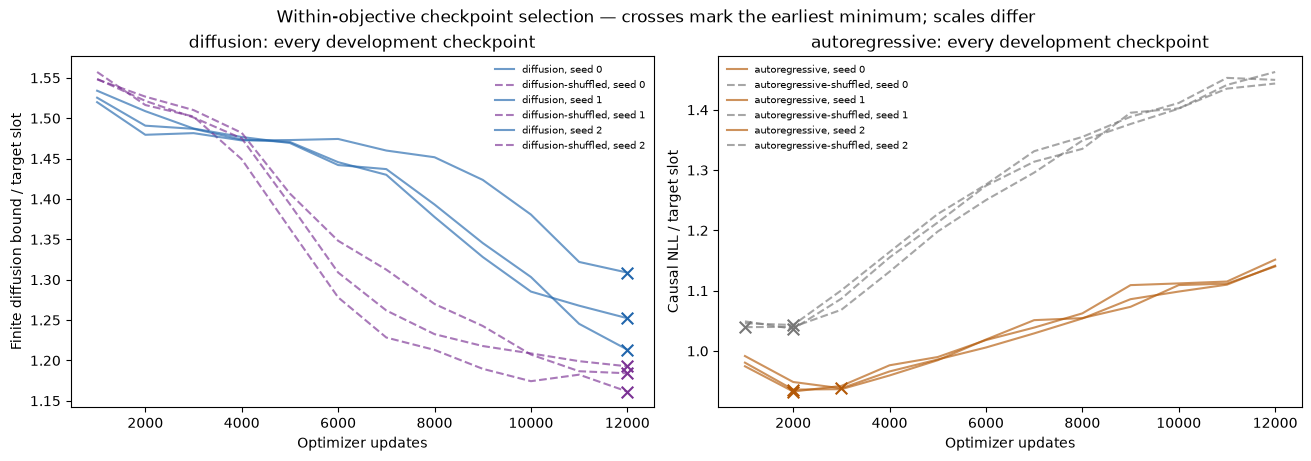

In [ ]:
def make_text_model():
    return TextTransformer(768, width=64, heads=4, layers=2, max_length=64)

if RUN_TEXT_STUDY:
    text_fits = []
    selected_checkpoints = []
    t.cuda.reset_peak_memory_stats()
    for training_seed in protocol["seeds"]:
        for kind, shuffled in (("diffusion",False),("diffusion",True),("autoregressive",False),("autoregressive",True)):
            label = kind + ("-shuffled" if shuffled else "")
            fit_directory = output_dir / "weights" / f"seed{training_seed}-{label}"
            fit_directory.mkdir(parents=True, exist_ok=False)
            def save_checkpoint(step, current_model, history):
                t.save(current_model.state_dict(), fit_directory / f"checkpoint-{step}.pt")
                print(training_seed, label, step, "development objective", round(history["development_objective"],5), flush=True)
            trained_model, fit = fit_text_model(make_text_model, training, development,
                kind=kind, shuffled=shuffled, seed=training_seed, mask_id=MASK_ID,
                total_steps=16, updates=protocol["updates"], batch_size=32, learning_rate=.002,
                weight_decay=.01, development_every=1000, checkpoint_callback=save_checkpoint)
            selected_path = fit_directory / "selected.pt"
            t.save(trained_model.state_dict(), selected_path)
            (fit_directory / "fit.json").write_text(json.dumps(fit,indent=2)+"\n")
            text_fits.append(fit)
            selected_checkpoints.append({"seed":training_seed,"label":label,
                "selected_step":fit["selected_step"],"selected_sha256":hashlib.sha256(selected_path.read_bytes()).hexdigest(),
                "endpoint_sha256":hashlib.sha256((fit_directory / "checkpoint-12000.pt").read_bytes()).hexdigest()})
            del trained_model
        same_seed = [f for f in text_fits if f["seed"]==training_seed]
        assert len({f["initial_parameters_sha256"] for f in same_seed}) == 1, "The four models must start from identical parameters."
        assert len({f["batch_indices_sha256"] for f in same_seed}) == 1, "The four models must see identical input minibatches."
    selection_path = output_dir / "checkpoint_selection.json"
    selection_path.write_text(json.dumps({"protocol_sha256":protocol_sha256,"final_loaded":False,
        "checkpoints":selected_checkpoints},indent=2)+"\n")
    selection_sha256 = hashlib.sha256(selection_path.read_bytes()).hexdigest()
    text_plotting.plot_training(text_fits, assets_dir)

## Signature Result — answers, controls and all sampling budgets

Only now load the frozen final rows. Run every declared condition and retain
individual token IDs, decoded words, EOS status and scores. The primary bars
show every seed separately; last-update bars show sensitivity to checkpoint
selection. The step curves keep random-order and shuffled-supervision controls.
Higher confidence or lower entropy alone cannot make an incorrect answer correct.

Before inspecting the plots, predict whether more steps will help each task.
Addition has one answer. Parentheses may have several valid continuations. QA
requires retrieving the queried fact rather than repeating a common color.
TinyStories has no unique target string, so the later gallery is the relevant
qualitative result and its reference edit distance has a narrower meaning.


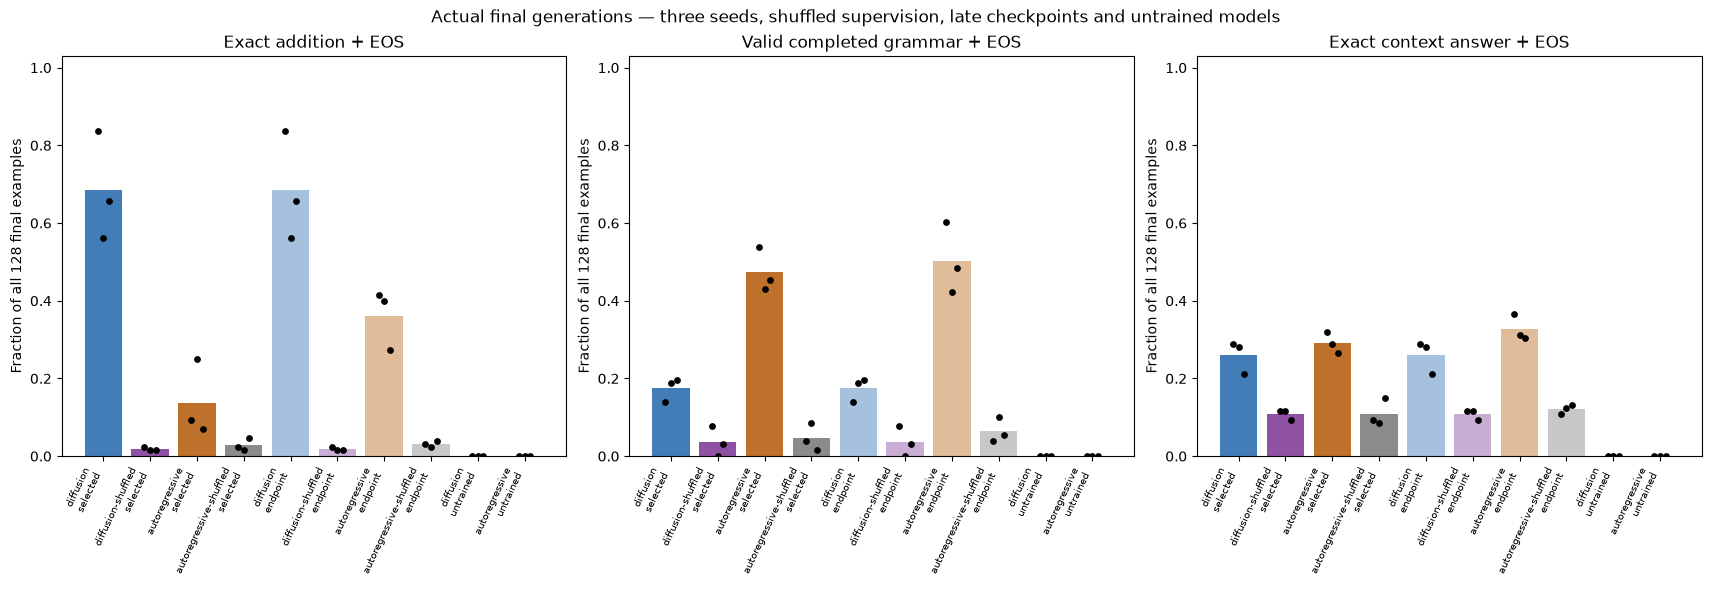
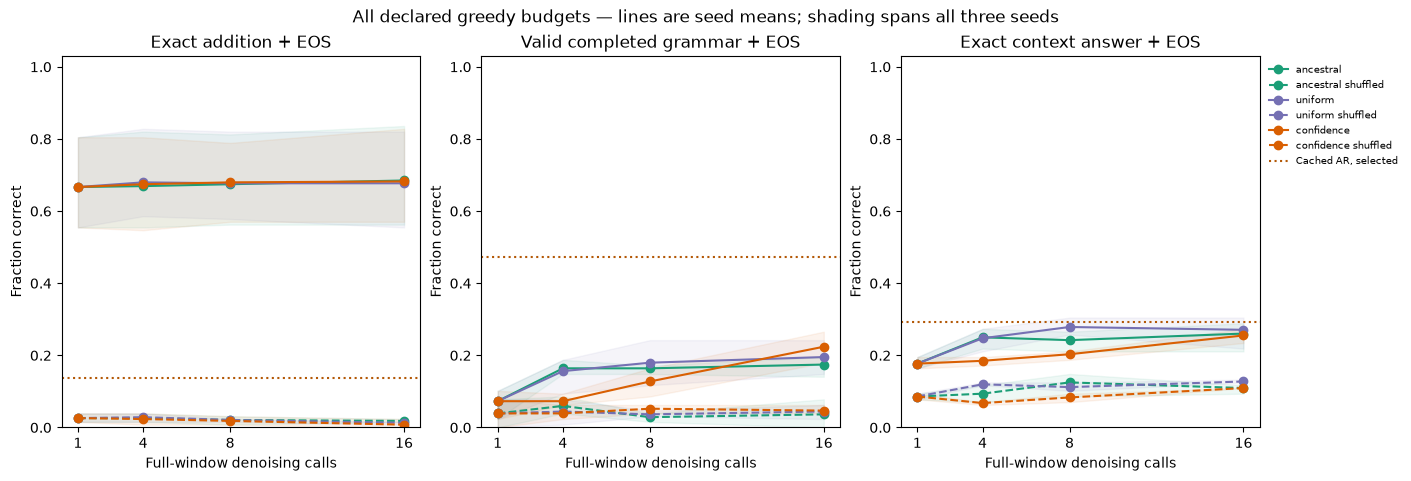
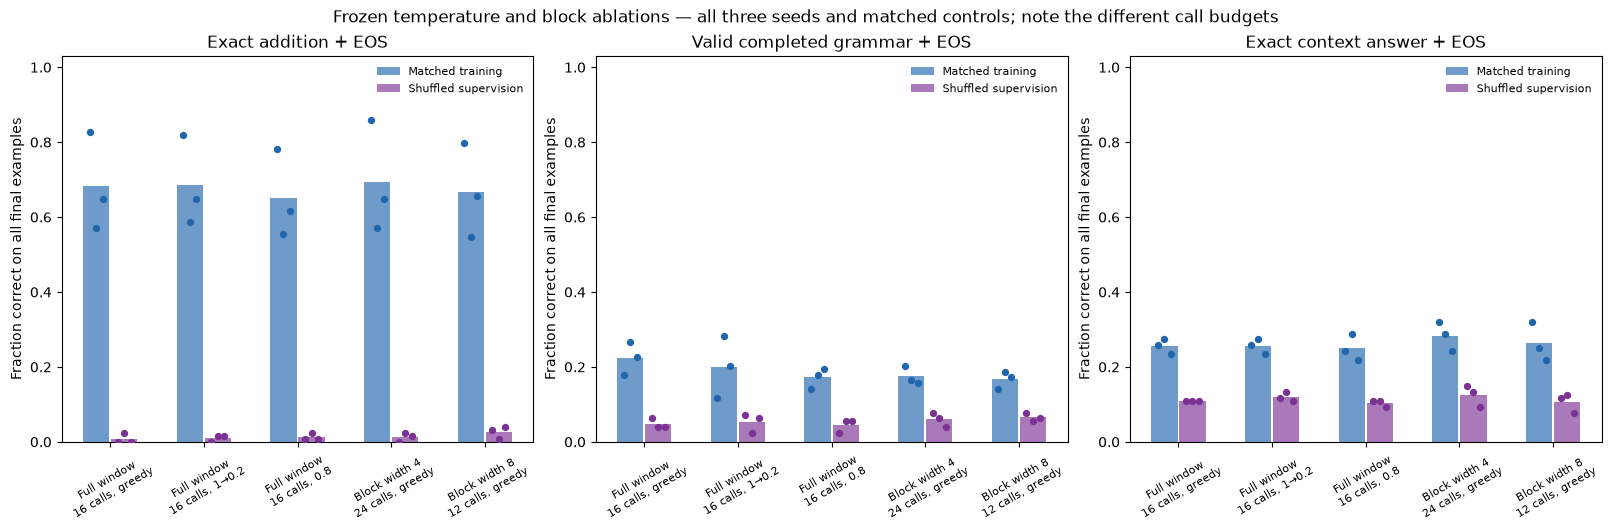
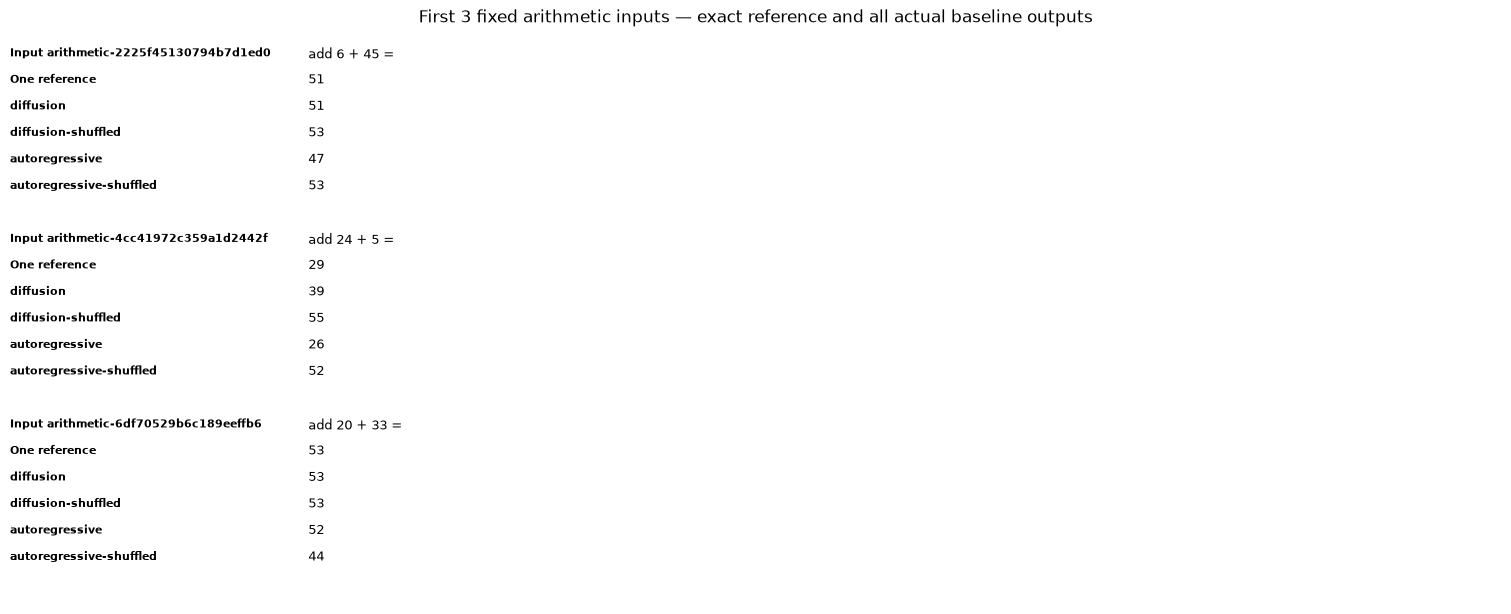

In [ ]:
def load_own_text_weights(seed, label, checkpoint):
    kind = label.removesuffix("-shuffled")
    with t.random.fork_rng(devices=[device.index or 0] if device.type=="cuda" else []):
        t.manual_seed(seed)
        model = make_text_model().to(device)
    if checkpoint != "untrained":
        directory = output_dir / "weights" / f"seed{seed}-{label}"
        name = "selected.pt" if checkpoint=="selected" else "checkpoint-12000.pt"
        model.load_state_dict(t.load(directory/name, weights_only=True, map_location=device))
    return model.eval()

if RUN_TEXT_STUDY:
    assert hashlib.sha256(protocol_path.read_bytes()).hexdigest() == protocol_sha256, "Do not change the protocol after fitting."
    assert hashlib.sha256(selection_path.read_bytes()).hexdigest() == selection_sha256, "Do not reselect checkpoints using final answers."
    final_rows = read_verified_split(data_directory, "final", data_provenance)
    assert len(final_rows)==512, "Keep all four final task sets."
    assert not ({r["id"] for r in final_rows} & {r["id"] for r in train_rows+development_rows}), "Final IDs must be disjoint."
    trace_ids = [row["id"] for task in ("parentheses","arithmetic","qa","story")
        for row in [r for r in final_rows if r["task"]==task][:2]]
    text_results = []
    generation_directory = output_dir / "generations"
    generation_directory.mkdir(exist_ok=False)
    for seed in protocol["seeds"]:
        for label in protocol["modes"]:
            kind = label.removesuffix("-shuffled")
            for checkpoint in ("selected","endpoint"):
                model = load_own_text_weights(seed,label,checkpoint)
                configs = diffusion_configs if kind=="diffusion" else ar_configs
                if checkpoint=="endpoint":
                    configs = [c for c in configs if c["name"] in {"ancestral-16-greedy","ar-greedy"}]
                for config in configs:
                    result = generate_text_examples(model,final_rows,tokenizer,kind=kind,seed=1000,
                        sampler=config.get("sampler","ancestral"),steps=config.get("steps",16),
                        temperatures=tuple(config["temperatures"]),block_size=config.get("block_size"),
                        batch_size=32,trace_ids=trace_ids)
                    record = {"seed":seed,"label":label,"kind":kind,"shuffled":label.endswith("-shuffled"),
                        "checkpoint":checkpoint,"config":config,"result":result}
                    text_results.append(record)
                    (generation_directory / f"{seed}-{label}-{checkpoint}-{config['name']}.json").write_text(json.dumps(record)+"\n")
                    print("Final generation",seed,label,checkpoint,config["name"],flush=True)
                del model
        for kind in protocol["untrained_baselines"]:
            model = load_own_text_weights(seed,kind,"untrained")
            config = next(c for c in (diffusion_configs if kind=="diffusion" else ar_configs)
                          if c["name"] in {"ancestral-16-greedy","ar-greedy"})
            result = generate_text_examples(model,final_rows,tokenizer,kind=kind,seed=1000,
                sampler=config.get("sampler","ancestral"),steps=config.get("steps",16),temperatures=(0.,0.),trace_ids=trace_ids)
            record = {"seed":seed,"label":kind,"kind":kind,"shuffled":False,"checkpoint":"untrained","config":config,"result":result}
            text_results.append(record)
            (generation_directory / f"{seed}-{kind}-untrained-{config['name']}.json").write_text(json.dumps(record)+"\n")
            del model
    assert len(text_results)==126, "All 42 frozen generation conditions per seed must be retained."
    text_plotting.plot_task_quality(text_results,assets_dir)
    text_plotting.plot_budget_quality(text_results,assets_dir)
    text_plotting.plot_temperature_blocks(text_results,assets_dir)
    text_plotting.plot_generation_gallery(final_rows,text_results,assets_dir,task="arithmetic",count=3,
        name="diffusion_text_arithmetic_gallery.png")

### Interpret the whole task matrix

In the first full run, primary diffusion addition accuracy averaged **57.8%**
across the three seeds, against **1.8%** for shuffled supervision. The stronger
causal result was parenthesis validity: **47.4%**, compared with diffusion's
**21.1%**. Both achieved only about **28–29%** on context-dependent QA. Retain
the three individual seed points; these are runs on the same data split, not
independent datasets or a confidence interval over tasks.

More denoising steps did not reliably improve addition. Block generation also
spends a different number of full-sequence calls: width four with four steps
per block costs 24 calls, while width eight costs 12. The temperature/block
panel keeps those costs in its labels and retains both supervision conditions.
Use the first three arithmetic examples to connect aggregate rates to words.

The last-update sensitivity bars matter: the development NLL selects an early
AR model, while later causal training improves some closed-task rates and
worsens the aggregate development objective. This study therefore compares
two declared checkpoint policies; it does not establish a universal ranking
of AR and diffusion architectures. The story gallery retains repetition and
malformed words. Input-dependent arithmetic success does not transfer into
fluent natural-language generation in this small model.

### Watch one fixed question all the way through

This is the first final QA example in source order, whether or not either model
answers it. Every target slot remains in the diagram. The initial all-MASK row
is state zero. The entropy curve averages **only still-masked slots** before
each call, using the untempered predictive distribution. The commitment panel
does not use the reference answer: even a confidently wrong token commits.
Gray trajectory cells are MASK; blue cells match the final emitted token,
including wrong answers. On this fixed QA example, both models answer wrongly.

<details><summary>Interpretation — an early error can be permanent</summary>

An absorbing model cannot rewrite a revealed token. A strong input-dependent
method can still fail this specific example; compare its full task denominator
before generalizing. The shuffled model can also emit real color words because
those words remain in its target marginals. For a low-entropy wrong answer,
inspect the logits and the conditioning facts rather than relabeling confidence
as knowledge.

</details>


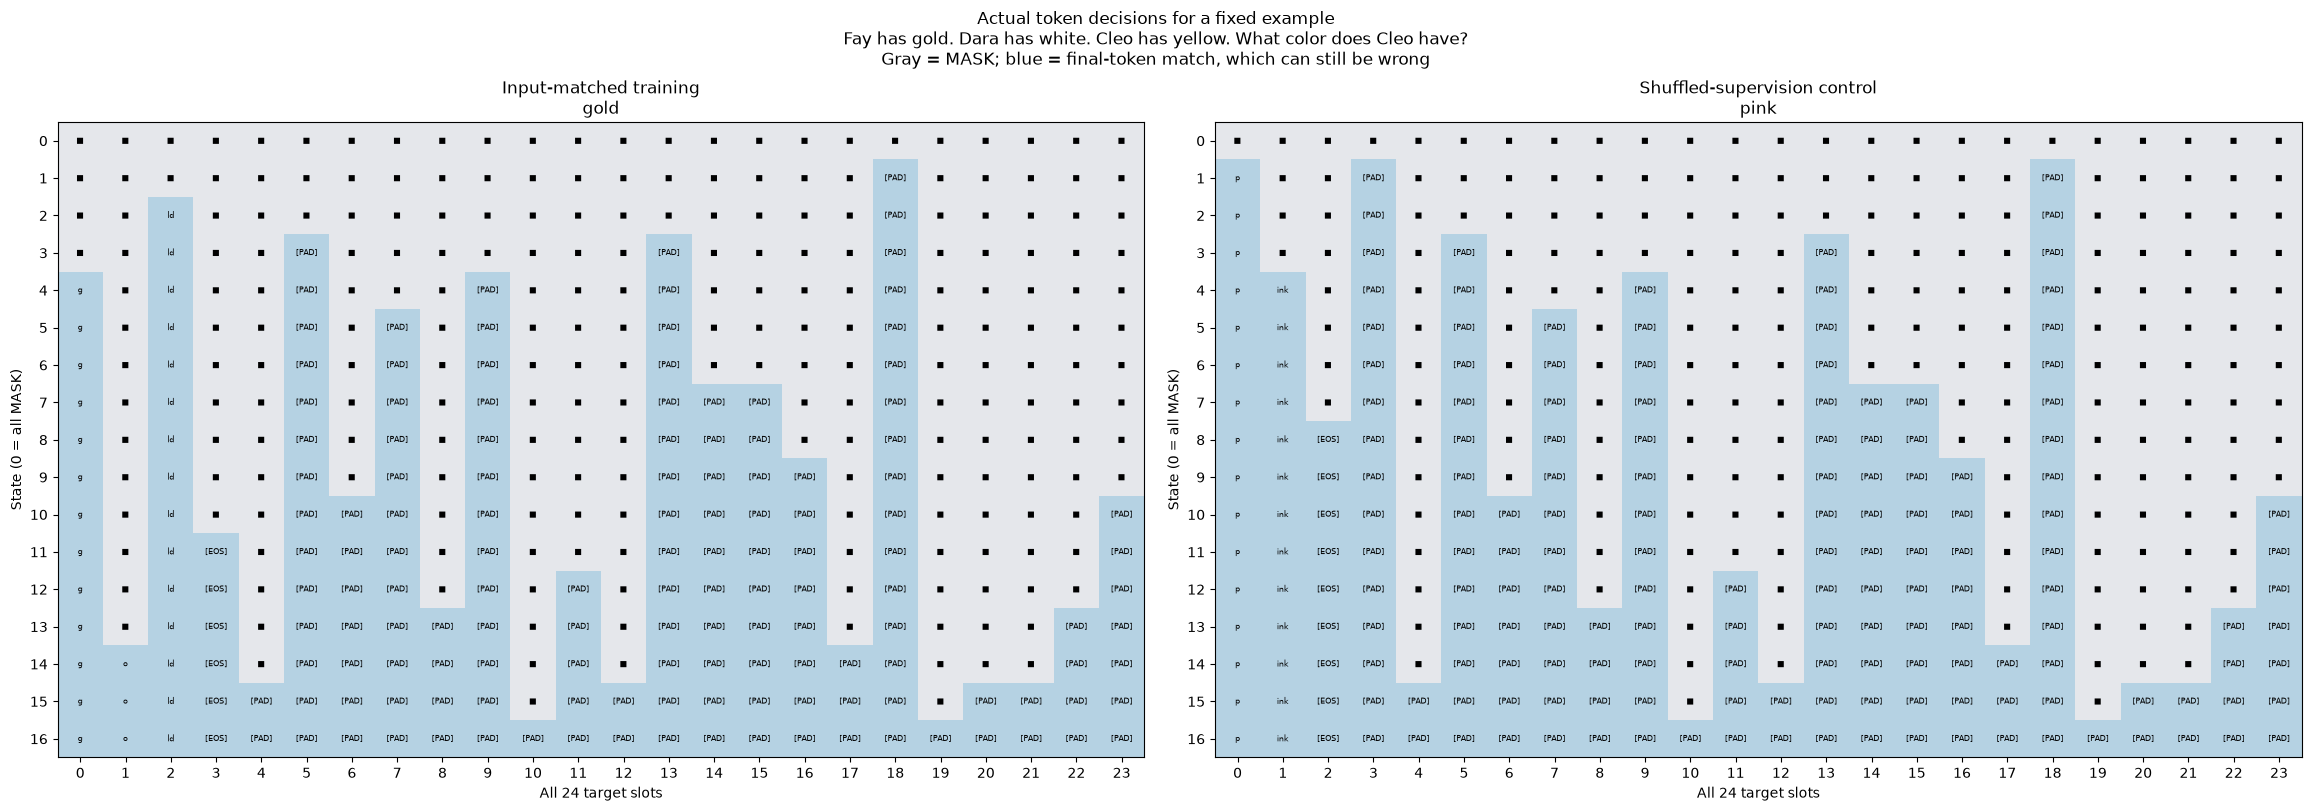
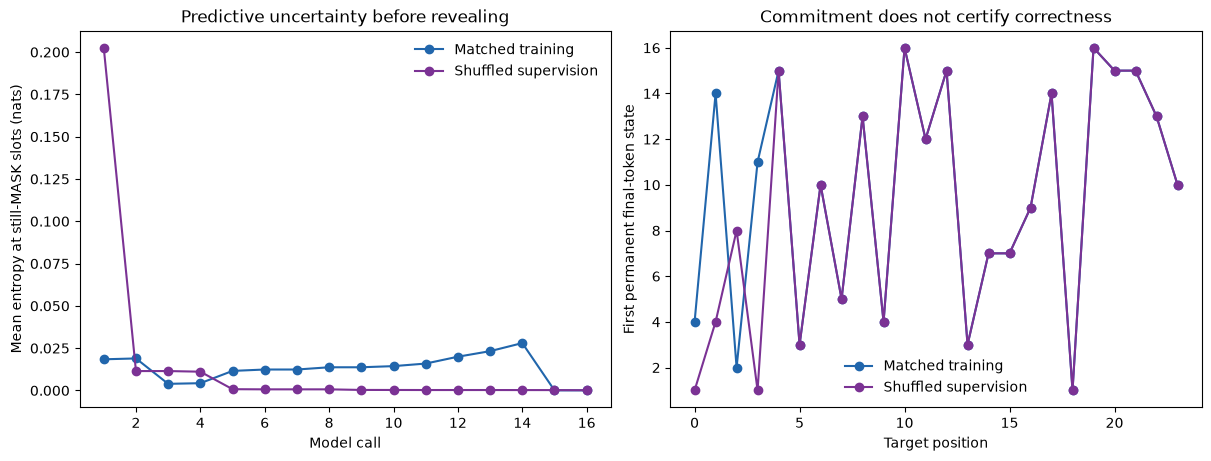
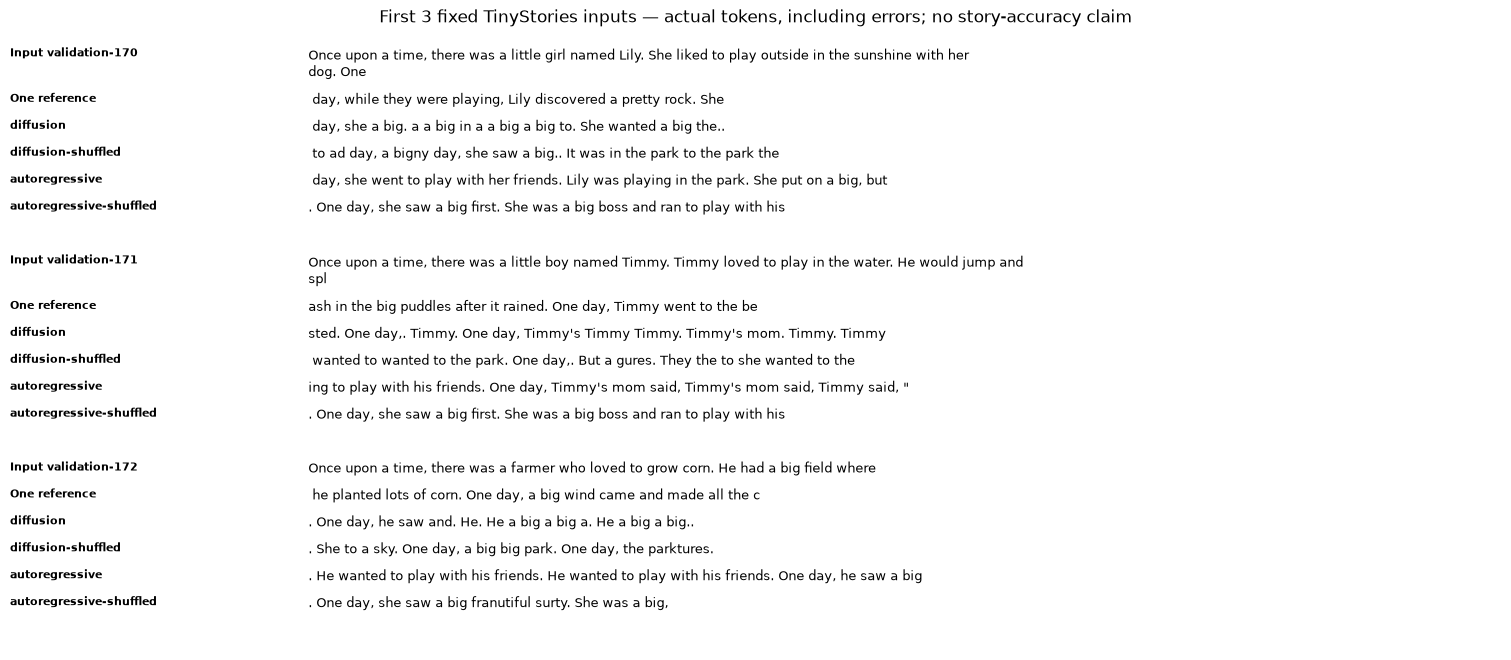

In [ ]:
if RUN_TEXT_STUDY:
    fixed_qa_id = next(r["id"] for r in final_rows if r["task"]=="qa")
    def primary_trace(label, example_id):
        run = next(r for r in text_results if r["seed"]==0 and r["label"]==label
            and r["checkpoint"]=="selected" and r["config"]["name"]=="ancestral-16-greedy")
        return next(r for r in run["result"]["traces"] if r["id"]==example_id)
    qa_trace = primary_trace("diffusion",fixed_qa_id)
    qa_control_trace = primary_trace("diffusion-shuffled",fixed_qa_id)
    print("Input:",qa_trace["prompt"])
    print("Reference:",next(r["answer"] for r in final_rows if r["id"]==fixed_qa_id))
    text_plotting.plot_trajectory_pair(qa_trace,qa_control_trace,tokenizer,assets_dir)
    text_plotting.plot_commitment(qa_trace,qa_control_trace,assets_dir)
    text_plotting.plot_generation_gallery(final_rows,text_results,assets_dir)

### Measure actual cost on the same batch

Use the first eight final examples of each task, a batch of 32 with the same
24 output slots. Stories generally use all slots; early EOS is still retained
for individual closed-task rows. AR may finish a batch early only if every row
has ended. Diffusion recomputes the full 64-position input at every call;
cached AR pays for one context prefill and then one new token at a time.

The timer excludes string decoding and figure storage for both methods. It
records all five synchronized repetitions after two warmups. Show both model
calls and milliseconds alongside actual arithmetic quality. Treat hardware,
batch size, model width and output length as part of the result.


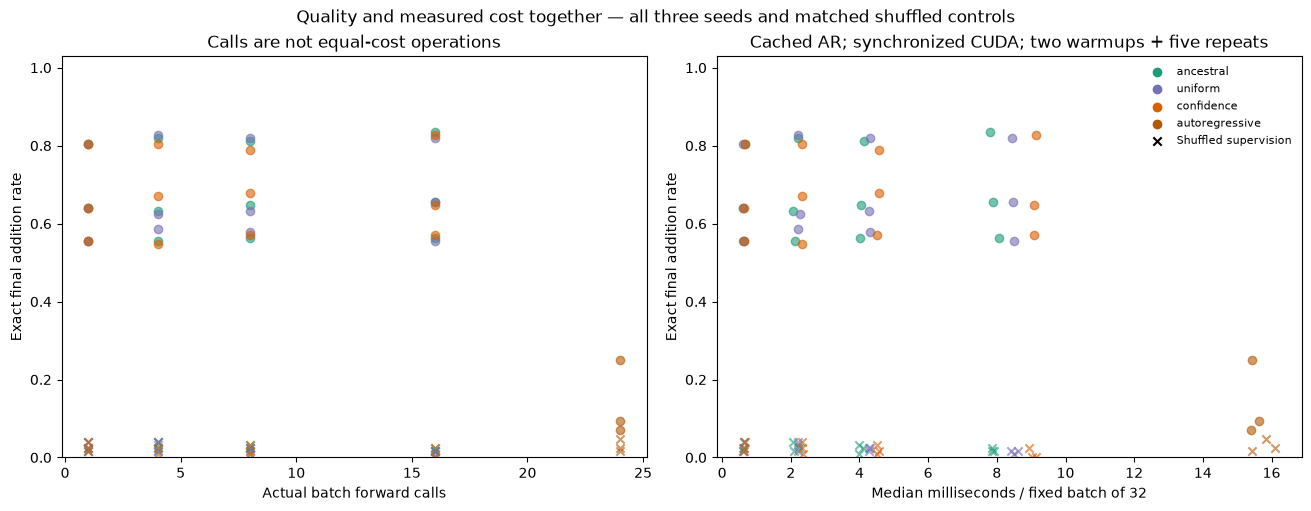

In [ ]:
if RUN_TEXT_STUDY:
    timing_rows = [row for task in ("parentheses","arithmetic","qa","story")
        for row in [r for r in final_rows if r["task"]==task][:8]]
    timing_context,timing_conditioning,timing_valid,timing_eligible = model_inputs_from_context(timing_rows,device)
    text_timings = []
    for seed in protocol["seeds"]:
        for label in protocol["modes"]:
            kind = label.removesuffix("-shuffled")
            model = load_own_text_weights(seed,label,"selected")
            configs = [c for c in (diffusion_configs if kind=="diffusion" else ar_configs)
                if c["temperatures"]==[0.,0.] and c.get("block_size") is None]
            for config in configs:
                def generate_for_timing():
                    generator = t.Generator(device=device).manual_seed(990)
                    if kind=="autoregressive":
                        tokens,lengths,records = sample_autoregressive(model,timing_context,timing_valid[:,:CONTEXT_SLOTS],
                            output_length=TARGET_SLOTS,mask_id=MASK_ID,eos_id=EOS_ID,pad_id=PAD_ID,
                            temperature=0.,use_cache=True,generator=generator,record_trace=False)
                    else:
                        def model_fn(tokens,p):return model(tokens,timing_valid,causal=False)[0]
                        full,states,records = sample_text_diffusion(model_fn,timing_conditioning,timing_eligible,MASK_ID,
                            steps=config["steps"],sampler=config["sampler"],temperatures=(0.,0.),
                            generator=generator,record_trace=False)
                        tokens = full[:,CONTEXT_SLOTS:]
                    return tokens,records
                measurement = measure_generation_latency(generate_for_timing,device=device,warmups=2,repeats=5)
                text_timings.append({"seed":seed,"label":label,"config":config["name"],"measurement":measurement})
            del model
    assert len(text_timings)==78, "Keep all three seeds, both supervision conditions, twelve diffusion budgets and cached AR."
    text_plotting.plot_cost_quality(text_results,text_timings,assets_dir)

## Try It Yourself — change the fact, not just the answer label

Change `play_color` and rerun. The prompt itself changes while other facts and
the queried person remain fixed. Compare the trained diffusion model with its
shuffled-supervision control and causal baseline. A changed output alone is
not success: both members should answer their own input correctly. This
two-example play is a microscope, not an additional held-out performance estimate.

In [ ]:
if RUN_TEXT_STUDY:
    play_color = "blue"  # choose a different color from Ada's original red
    play_facts = {"Ada":"red","Ben":"green","Cleo":"gold"}
    play_examples = []
    for index,color in enumerate(("red",play_color)):
        facts = {**play_facts,"Ada":color}
        question = " ".join(f"{person} has {value}." for person,value in facts.items()) + " What color does Ada have?"
        play_examples.append({"id":f"play-qa-{index}","split":"play","task":"qa", "prompt":question,
            "answer":color,"facts":facts,"query":"Ada"})
    encoded_play = text_data.encode_examples({"play":play_examples},{"play":[]},tokenizer)["play"]
    play_results = []
    for label in ("diffusion","diffusion-shuffled","autoregressive"):
        kind = label.removesuffix("-shuffled")
        model = load_own_text_weights(0,label,"selected")
        result = generate_text_examples(model,encoded_play,tokenizer,kind=kind,sampler="ancestral",steps=16,
            temperatures=(0.,0.),trace_ids=[r["id"] for r in encoded_play])
        play_results.append({"play":"fact edit","label":label,"result":result})
        del model
    display(pd.DataFrame([{"model":r["label"],"input":encoded_play[i]["prompt"],"expected":encoded_play[i]["answer"],
        "generated":outcome["text"],"correct":outcome["exact_answer"]}
        for r in play_results for i,outcome in enumerate(r["result"]["rows"])]))

## Try It Yourself — change the reveal schedule on fixed weights

Choose a step count, temperature pair and block width. The number of calls is
`steps × ceil(24 / block_width)` when block generation is enabled, so fewer
steps per block need not mean less work. Compare against the matched shuffled
model and inspect both actual strings and token decisions. Previously completed
blocks stay fixed. A short block can improve local consistency while making
global structure harder to coordinate.


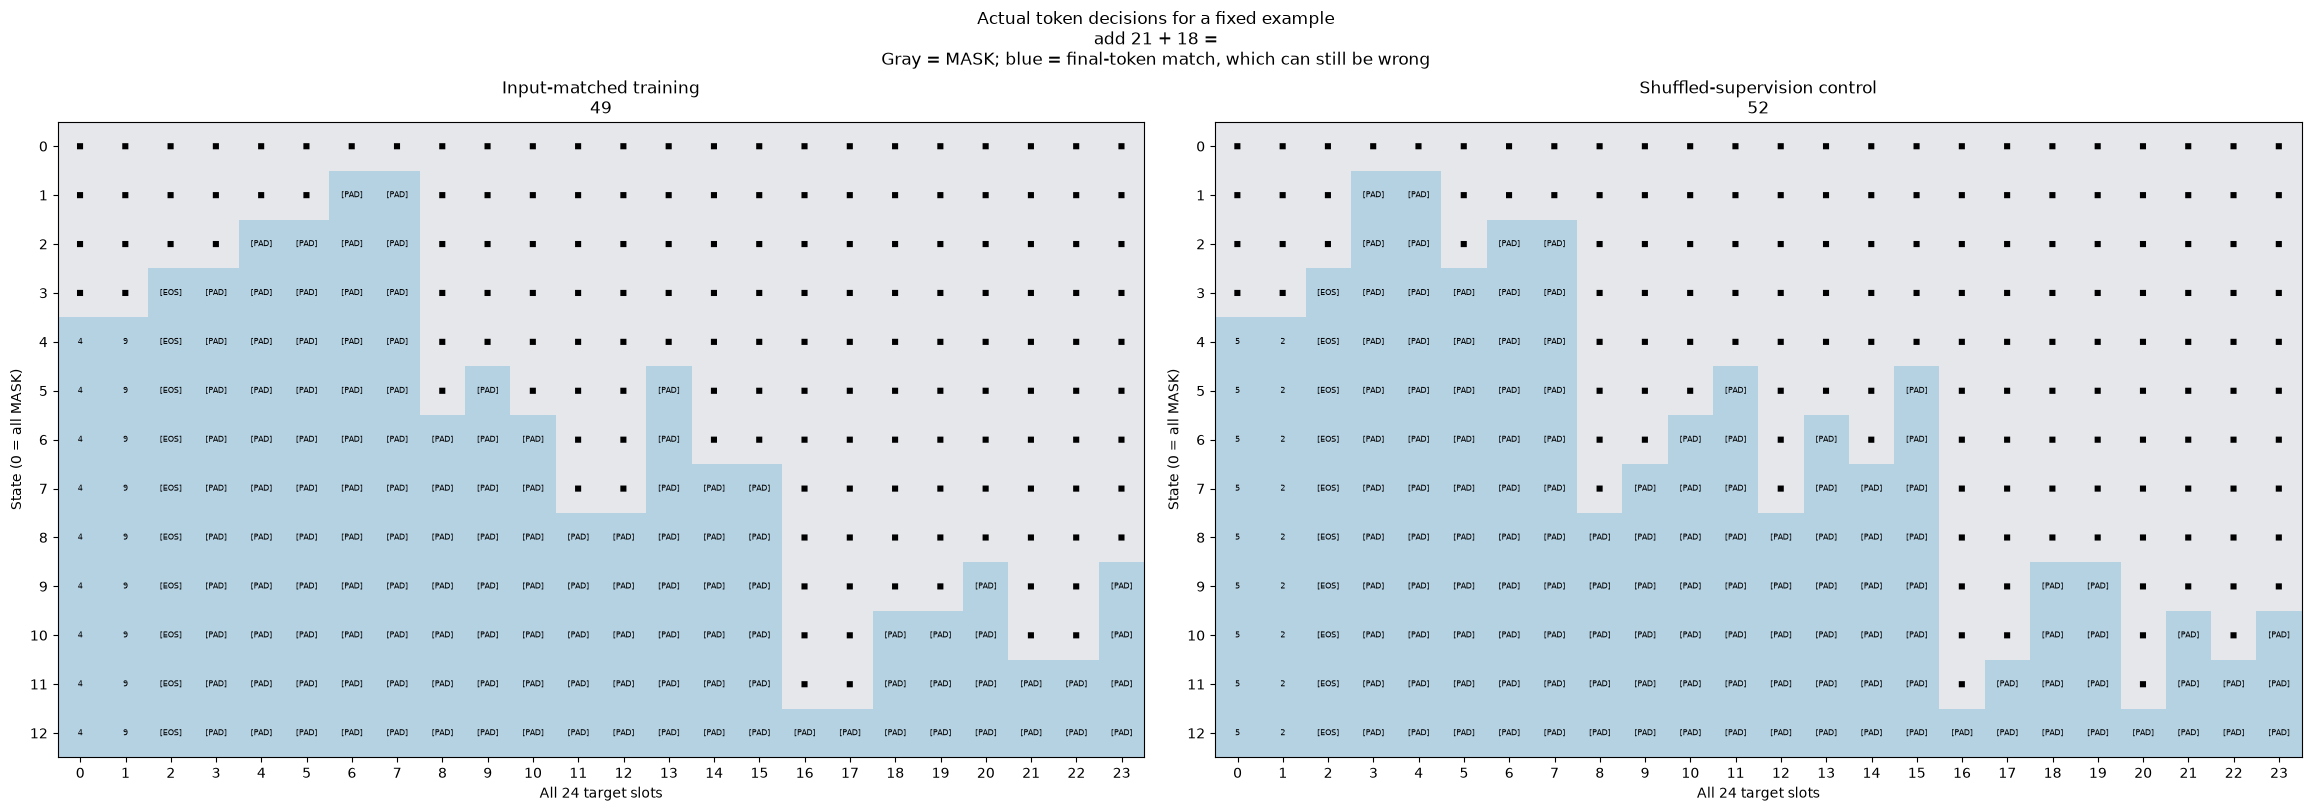

In [ ]:
if RUN_TEXT_STUDY:
    play_steps = 4
    play_sampler = "confidence"  # also ancestral / uniform
    play_temperatures = (1.,.2)
    play_block_size = 8  # None means all 24 target slots together
    play_input = [next(r for r in development_rows if r["task"]=="arithmetic")]
    schedule_results = []
    for label in ("diffusion","diffusion-shuffled"):
        model = load_own_text_weights(0,label,"selected")
        result = generate_text_examples(model,play_input,tokenizer,kind="diffusion",seed=17,sampler=play_sampler,
            steps=play_steps,temperatures=play_temperatures,block_size=play_block_size,trace_ids=[play_input[0]["id"]])
        schedule_results.append(result)
        play_results.append({"play":"schedule edit","label":label,"result":result})
        print(label, "input",play_input[0]["prompt"],"output",result["rows"][0]["text"],
            "correct",result["rows"][0]["exact_answer"],"calls",result["total_batch_forward_calls"])
        del model
    text_plotting.plot_trajectory_pair(schedule_results[0]["traces"][0],schedule_results[1]["traces"][0],
        tokenizer,assets_dir,name="diffusion_text_schedule_play.png")

## Try It Yourself — continue the same real prefix

Choose another development story index and temperature. Both methods receive
the same tokenized prefix and generate actual tokens from fixed weights.
Display the shuffled models too: they have seen the same target-story marginal,
so plausible words alone do not prove context use. Compare the first new phrase,
repetition, subject consistency and malformed tokens. Keep the reference as one
observed continuation, not a definition of every acceptable story.

In [ ]:
if RUN_TEXT_STUDY:
    play_story_index = 0
    play_story_temperature = .8
    story_play_input = [[r for r in development_rows if r["task"]=="story"][play_story_index]]
    story_play_rows = []
    for label in protocol["modes"]:
        kind = label.removesuffix("-shuffled")
        model = load_own_text_weights(0,label,"selected")
        result = generate_text_examples(model,story_play_input,tokenizer,kind=kind,seed=19,sampler="ancestral",steps=16,
            temperatures=(play_story_temperature,play_story_temperature),trace_ids=[story_play_input[0]["id"]])
        play_results.append({"play":"story continuation","label":label,"result":result})
        story_play_rows.append({"model":label,"generated continuation":result["rows"][0]["text"]})
        del model
    print("Shared prefix:",story_play_input[0]["prompt"])
    print("One source continuation:",story_play_input[0]["reference_continuation"])
    display(pd.DataFrame(story_play_rows))
    # Archive supporting evidence after the actual figures and all play cells.
    completed_text_study = {"protocol":protocol,"protocol_sha256":protocol_sha256,
        "selection_sha256":selection_sha256,"selection":selected_checkpoints,"data_provenance":data_provenance,
        "fits":text_fits,"results":text_results,"timings":text_timings,"plays":play_results,
        "final_ids":[r["id"] for r in final_rows],"peak_vram_gb":t.cuda.max_memory_allocated()/1024**3,
        "model_device":t.cuda.get_device_name(0),"own_answer_training":True,"final_used_for_selection":False}
    (output_dir / "completed_text_study.json.gz").write_bytes(gzip.compress(json.dumps(completed_text_study).encode(),mtime=0))

## Real-model and paper connection

[The MDLM paper](https://arxiv.org/abs/2406.07524v2) and its
[authors’ implementation](https://github.com/kuleshov-group/mdlm) motivate the
absorbing process, exclusion of MASK from clean predictions and copying of
visible tokens. The source comparison uses commit
`c112c526d193436838c98d81455ee51f90309470`. Our exact finite-T objective is derived
and independently checked above; it is not mislabeled as their continuous-time
loss or a reproduction of their language-model quality.

The real-text source is [TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories),
revision `f54c09fd23315a6f9c86f9dc80f725de7d8f9c64`. The data recipe records both
parquet hashes, training-only tokenizer inputs, all chosen IDs and rejected
duplicate tokenized contexts. The first train shard supplies training text;
disjoint validation rows supply development and final text. Short generated
continuations and reference edit distances measure a bounded student experiment.

# ☆ Bonus

## Real-model connection: DiffusionGemma NVFP4

This final cell displays the committed, real local generation artifact for the pinned NVIDIA NVFP4 checkpoint. It proves one released-checkpoint prompt generated on the RTX 5090 Laptop GPU. It does not prove denoising-step activation access, diffusion patching, quality parity, throughput, or BF16 loading on 24 GB.

The isolated vLLM runtime uses its own torch/CUDA stack because the available vLLM build needs `torch 2.11.0+cu130`, not the course's `torch 2.15.0+cu134`.

In [ ]:
proof = json.loads((section_dir / "artifacts" / "diffusiongemma_vllm_probe.json").read_text())

proof_table = pd.DataFrame([
    {"field": "model revision", "value": Path(proof["model"]).name},
    {"field": "runtime", "value": f"vLLM {proof['vllm_version']} / torch {proof['torch_version']} / CUDA {proof['torch_cuda_version']}"},
    {"field": "GPU", "value": proof["gpu_name"]},
    {"field": "load time", "value": f"{proof['load_seconds']:.2f} s"},
    {"field": "generation time", "value": f"{proof['generate_seconds']:.2f} s"},
])

display(proof_table)

print("Prompt:", proof["prompt"])

print("Output:", proof["output"])

assert proof["output"].strip() and proof["cuda_available"]

## Limitations and further experiments

The controlled string grammar, arithmetic range, QA templates, tokenizer and
24-token continuation budget delimit what this study can show. The parenthesis
generator is not uniform over Catalan strings. Real stories can share semantic
themes despite exact normalized-text/context deduplication. Three initialization
seeds on one split are not three independent datasets.

Task-matched shuffled supervision preserves answer marginals and can learn
unconditional language structure. It should fail input-dependent arithmetic or
QA, not necessarily every loss or fluency statistic. Keep unexpectedly strong
controls. Greedy decoding, confidence reveal and block generation can change
quality and computational work in different directions.

The pinned DiffusionGemma NVFP4 artifact proves one actual local generation.
Its isolated vLLM runtime still lacks the denoising-step hidden-state access
needed for the selected activation-capture and patching exercises. Those remain
unfinished; this notebook does not substitute a loading proof for them.

After reproducing the fixed study, propose one development-only ablation:
explicit time embeddings, a longer answer window, changed training task weights,
or a new checkpoint objective. State a prediction and a failure criterion first.
Preserve the original run so changing several choices cannot silently improve
the reported final result.